# Basic Data Analysis

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os
import glob

In [2]:
!ls data_hackathon_baywa_re/

ls: data_hackathon_baywa_re/: No such file or directory


In [3]:
# ========================================
folder_path = "../data"
# ========================================


files = sorted(f for f in glob.glob(os.path.join(folder_path, "*_data.xlsx"))
               if not os.path.basename(f).startswith("~$"))

full_idx = pd.date_range("2026-07-01 00:00", "2026-09-30 23:50", freq="10min")
vars_ = ["wind_speed", "wind_direction", "ambient_temperature", "air_pressure", "wind_speed_stddev"]

data = {}
for f in files:
    df = pd.read_excel(f)
    name = df["turbine_name"].iloc[0]          # trust the column, not the file name
    d = df.set_index("timestamp").reindex(full_idx)   # absent rows become NaN rows
    d["row_absent"] = ~full_idx.isin(df["timestamp"])
    data[name] = d
print("Loaded:", list(data))

def period(ts):
    if ts < pd.Timestamp("2026-09-01"): return "train"
    if ts < pd.Timestamp("2026-09-04"): return "hidden_test"
    if ts < pd.Timestamp("2026-09-10"): return "shown_test"
    return "after_test"
periods = pd.Series([period(t) for t in full_idx], index=full_idx)

Loaded: ['H1', 'H2', 'H3', 'H4', 'H5', 'O1', 'O2', 'T1', 'T2', 'T3']


In [4]:
rows = []
for name, d in data.items():
    r = {"turbine": name, "rows_absent": d["row_absent"].sum()}
    for v in vars_:
        r[f"{v}_%NaN"] = round(d[v].isna().mean() * 100, 2)
    r["ws_zero"] = (d["wind_speed"] == 0).sum()
    r["temp_zero"] = (d["ambient_temperature"] == 0).sum()
    r["pressure_constant"] = d["air_pressure"].nunique() <= 1
    rows.append(r)
display(pd.DataFrame(rows).set_index("turbine"))

# Wind speed missing % by period
display(pd.DataFrame({n: d["wind_speed"].isna().groupby(periods).mean() * 100
                      for n, d in data.items()}).T.round(1)
        [["train", "hidden_test", "shown_test", "after_test"]])

,rows_absent,wind_speed_%NaN,wind_direction_%NaN,ambient_temperature_%NaN,air_pressure_%NaN,wind_speed_stddev_%NaN,ws_zero,temp_zero,pressure_constant
turbine,,,,,,,,,
H1,288,4.33,4.33,4.45,3.17,4.33,0,0,False
H2,288,3.05,3.05,3.15,3.05,3.05,0,0,False
H3,288,3.08,3.08,3.12,3.08,3.08,0,0,False
H4,288,3.27,3.27,3.36,3.27,3.27,0,0,False
H5,288,3.08,3.08,3.16,3.08,3.08,0,0,False
O1,288,3.16,3.19,3.28,3.16,100.00,4,0,True
O2,288,2.99,3.00,3.09,2.98,100.00,6,0,True
T1,288,6.59,6.59,6.72,6.39,6.59,3,3,False
T2,288,6.24,6.24,6.45,6.24,6.24,2,2,False


,train,hidden_test,shown_test,after_test
H1,5.9,0.0,0.0,1.6
H2,4.2,0.0,0.0,0.8
H3,4.2,0.0,0.0,1.1
H4,4.4,0.0,0.0,1.3
H5,4.2,0.0,0.0,1.0
O1,4.3,0.0,0.0,1.1
O2,4.2,0.0,0.0,0.7
T1,4.6,100.0,0.0,1.1
T2,4.2,100.0,0.0,0.6
T3,4.0,100.0,0.0,1.3


## Train Test Evaluation

In [5]:
check = []
for name, d in data.items():
    t = d.index[d["test_set"] == True]
    target_nan = d["wind_speed"].isna()
    check.append({
        "turbine": name,
        "test_start": t.min(), "test_end": t.max(), "test_steps": len(t),
        "hidden_NaN_steps": target_nan[(d.index >= "2026-09-01") & (d.index < "2026-09-04")].sum(),
        "shown_NaN_steps": target_nan[(d.index >= "2026-09-04") & (d.index < "2026-09-10")].sum(),
        "first_ts": d.index[~d["row_absent"]].min(), "last_ts": d.index[~d["row_absent"]].max(),
    })
display(pd.DataFrame(check).set_index("turbine"))

# Masks to reuse
idx = full_idx
hidden = (idx >= "2026-09-01") & (idx < "2026-09-04")
shown  = (idx >= "2026-09-04") & (idx < "2026-09-10")
train_dev   = ~hidden & ~shown          # for validation runs
train_final = ~hidden                   # for the final submission fit

,test_start,test_end,test_steps,hidden_NaN_steps,shown_NaN_steps,first_ts,last_ts
turbine,,,,,,,
H1,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H2,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H3,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H4,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
H5,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
O1,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
O2,2026-09-01,2026-09-09 23:50:00,1296,0,0,2026-07-01,2026-09-30 23:50:00
T1,2026-09-01,2026-09-09 23:50:00,1296,432,0,2026-07-01,2026-09-30 23:50:00
T2,2026-09-01,2026-09-09 23:50:00,1296,432,0,2026-07-01,2026-09-30 23:50:00


In [6]:
print(f"Columns are: {data['H1'].columns}") 

Columns are: Index(['turbine_name', 'wind_speed', 'wind_direction', 'ambient_temperature',
       'air_pressure', 'wind_speed_stddev', 'test_set', 'row_absent'],
      dtype='object')


### Are the power curve file all the same

In [7]:
t1_power_path = os.path.join(folder_path, "T1_power_curve.xlsx")
t2_power_path = os.path.join(folder_path, "T2_power_curve.xlsx")
t3_power_path = os.path.join(folder_path, "T3_power_curve.xlsx")

# Are the power curve file all the same
t1_power = pd.read_excel(t1_power_path)
t2_power = pd.read_excel(t2_power_path)
t3_power = pd.read_excel(t3_power_path)


# Check whether all three are identical
# Compare only wind_speed and power
cols = ["wind_speed", "power"]

print("T1 == T2:", t1_power[cols].equals(t2_power[cols]))
print("T1 == T3:", t1_power[cols].equals(t3_power[cols]))
print("T2 == T3:", t2_power[cols].equals(t3_power[cols]))

T1 == T2: True
T1 == T3: True
T2 == T3: True


All the power curve are the same so we can use it as is, and we can maybe interporlate if they are between values.

## Training Data Preparation

In [8]:
def clean(d, stuck_steps=6):
    ''' 
    Set values tp Values to NaN if they are:
    '''
    d = d.copy()
    d["flag"] = ""

    # a) exactly 0.0 m/s average = logger error (temp is also 0 in T rows)
    zero_row = d["wind_speed"] == 0
    d.loc[zero_row, vars_] = np.nan
    d.loc[zero_row, "flag"] += "zero_ws;"

    # b) physically impossible values
    bad_ws = (d["wind_speed"] < 0) | (d["wind_speed"] > 40)
    d.loc[bad_ws, ["wind_speed", "wind_speed_stddev"]] = np.nan
    d.loc[bad_ws, "flag"] += "ws_out_of_range;"
    d.loc[(d["wind_direction"] < 0) | (d["wind_direction"] > 360), "wind_direction"] = np.nan

    # c) stuck sensor: same wind speed for >= 1 hour
    ws_ = d["wind_speed"]
    run_len = ws_.groupby((ws_ != ws_.shift()).cumsum()).transform("size")
    stuck = ws_.notna() & (run_len >= stuck_steps)
    d.loc[stuck, "wind_speed"] = np.nan
    d.loc[stuck, "flag"] += "stuck;"

    # d) constant pressure = placeholder (O park)
    if d["air_pressure"].nunique(dropna=True) <= 1:
        d["air_pressure"] = np.nan
        d["flag"] += "pressure_placeholder;"
    return d

data_clean = {n: clean(d) for n, d in data.items()} 

summary = pd.DataFrame({n: {"zero_ws": d["flag"].str.contains("zero_ws").sum(),
                            "out_of_range": d["flag"].str.contains("ws_out_of_range").sum(),
                            "stuck": d["flag"].str.contains("stuck").sum(),
                            "pressure_placeholder": d["air_pressure"].isna().all()}
                        for n, d in data_clean.items()}).T
display(summary)

,zero_ws,out_of_range,stuck,pressure_placeholder
H1,0,0,0,False
H2,0,0,0,False
H3,0,0,0,False
H4,0,0,0,False
H5,0,0,0,False
O1,4,0,6,True
O2,6,0,0,True
T1,3,0,0,False
T2,2,0,0,False
T3,4,0,0,False


In [9]:
targets = [n for n in data_clean if n.startswith("T")]
refs    = [n for n in data_clean if not n.startswith("T")]

wide = {v: pd.DataFrame({n: data_clean[n][v] for n in data_clean}) for v in vars_}
ws = wide["wind_speed"]

print(f"=== Wind Speed Summary ===")
print("Targets:", targets, "| References:", refs)
display(ws.describe().T.round(2))

=== Wind Speed Summary ===
Targets: ['T1', 'T2', 'T3'] | References: ['H1', 'H2', 'H3', 'H4', 'H5', 'O1', 'O2']


,count,mean,std,min,25%,50%,75%,max
H1,12674.0,5.77,2.16,0.31,4.18,5.72,7.26,15.83
H2,12844.0,5.72,2.22,0.26,4.11,5.61,7.17,17.06
H3,12840.0,6.28,2.41,0.31,4.44,6.33,7.99,17.73
H4,12815.0,5.83,2.21,0.27,4.18,5.80,7.29,20.26
H5,12840.0,6.42,2.42,0.34,4.55,6.43,8.23,17.57
O1,12819.0,6.22,2.58,0.10,4.40,6.00,7.80,22.50
O2,12846.0,6.09,2.69,0.10,4.20,6.00,7.70,21.70
T1,12372.0,5.34,2.15,0.39,3.84,5.11,6.66,17.02
T2,12419.0,5.66,2.26,0.44,4.04,5.50,7.19,16.88
T3,12417.0,5.33,2.08,0.40,3.90,5.19,6.63,16.99


### Dealing with Nan in windspeed

For short missing values,we can maybe interpolate, but for longer gap, it is difficult

In [10]:
raw_t1 = pd.read_excel(os.path.join(folder_path, "T1_data.xlsx"))
print("File timestamp dtype:", raw_t1["timestamp"].dtype)
print("File first rows:\n", raw_t1.head(3))
print("File wind NaN:", raw_t1["wind_speed"].isna().sum(), "of", len(raw_t1))

print("\ndata['T1'] wind NaN:", data["T1"]["wind_speed"].isna().sum(), "of", len(data["T1"]))
print("data['T1'] row_absent True:", data["T1"]["row_absent"].sum())
print("data_clean['T1'] row_absent True:", data_clean["T1"]["row_absent"].sum())

File timestamp dtype: datetime64[ns]
File first rows:
   turbine_name           timestamp  wind_speed  wind_direction  \
0           T1 2026-07-01 00:00:00    4.865286        124.9424   
1           T1 2026-07-01 00:10:00    3.804249        119.1656   
2           T1 2026-07-01 00:20:00    2.952448        142.4393   

   ambient_temperature  air_pressure  wind_speed_stddev  test_set  
0             17.26312      1001.278           0.924104     False  
1             17.42854      1001.276           0.583860     False  
2             17.60092      1001.283           0.950662     False  
File wind NaN: 585 of 12960

data['T1'] wind NaN: 873 of 13248
data['T1'] row_absent True: 288
data_clean['T1'] row_absent True: 288


In [11]:
def gap_table(s):
    """One row per consecutive run of NaN: start, end, length."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    g = s.index.to_series()[isna].groupby(run_id[isna]).agg(["first", "last", "size"])
    g.columns = ["start", "end", "steps"]
    g["hours"] = g["steps"] / 6
    return g.reset_index(drop=True)

ws_raw = pd.DataFrame({n: data[n]["wind_speed"] for n in data_clean})
absent = data_clean[targets[0]]["row_absent"]          # same absent rows in every file
all_gaps = []
for n in ws_raw.columns:
    g = gap_table(ws_raw[n])
    g["turbine"] = n
    g["kind"] = np.select(
        [g["start"].ge("2026-09-01") & g["end"].lt("2026-09-04"),
         absent.reindex(g["start"]).values & absent.reindex(g["end"]).values],
        ["hidden_test", "rows_absent_3-4_Aug"],
        "real_gap")
    all_gaps.append(g)
all_gaps = pd.concat(all_gaps, ignore_index=True)

# Count real gaps by length (excludes the hidden test and the absent 3-4 Aug rows)
bins   = [0, 1, 3, 12, 36, 10_000]
labels = ["10 min", "20-30 min (filled)", "40 min-2 h", "2-6 h", "> 6 h"]
real = all_gaps[all_gaps["kind"] == "real_gap"].copy()
real["length"] = pd.cut(real["steps"], bins=bins, labels=labels)
counts = real.pivot_table(index="turbine", columns="length", values="steps",
                          aggfunc="size", fill_value=0, observed=False)
counts["missing steps total"] = real.groupby("turbine")["steps"].sum()
display(counts)

# Every gap longer than 30 min, in time order
long_gaps = all_gaps[all_gaps["steps"] > 3].sort_values(["start", "turbine"]).copy()
long_gaps["hours"] = long_gaps["hours"].round(1)
display(long_gaps[["turbine", "start", "end", "hours", "kind"]])

length,10 min,20-30 min (filled),40 min-2 h,2-6 h,> 6 h,missing steps total
turbine,,,,,,
H1,128,1,0,0,2,286
H2,114,1,0,0,0,116
H3,116,2,0,0,0,120
H4,145,0,0,0,0,145
H5,116,2,0,0,0,120
O1,125,3,0,0,0,131
O2,108,0,0,0,0,108
T1,117,3,0,1,0,153
T2,105,1,0,0,0,107


,turbine,start,end,hours,kind
20,H1,2026-07-13 23:40:00,2026-07-14 09:50:00,10.3,real_gap
21,H1,2026-07-14 10:20:00,2026-07-15 01:50:00,15.7,real_gap
46,H1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
182,H2,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
297,H3,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
422,H4,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
567,H5,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
687,O1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
810,O2,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug
920,T1,2026-08-03 00:00:00,2026-08-04 23:50:00,48.0,rows_absent_3-4_Aug


In [12]:
def fill_short_gaps(s, max_gap=3):
    """Linear interpolation only inside gaps of <= max_gap steps (30 min)."""
    isna = s.isna()
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform("size")
    filled = s.interpolate(method="time", limit_area="inside")
    return s.where(~(isna & (run_len <= max_gap)), filled)

before = ws[refs].isna().sum()

for v in ["wind_speed", "ambient_temperature", "air_pressure", "wind_speed_stddev"]:
    for r in refs:
        wide[v][r] = fill_short_gaps(wide[v][r])

# Also Interpolate wind directions, use sin and cos because the direction is circular (0-360 degrees)
rad = np.deg2rad(wide["wind_direction"][refs])
sin_f = np.sin(rad).apply(fill_short_gaps)
cos_f = np.cos(rad).apply(fill_short_gaps)
wide["wind_direction"][refs] = np.rad2deg(np.arctan2(sin_f, cos_f)) % 360

ws = wide["wind_speed"]
display(pd.DataFrame({"NaN before": before, "NaN after": ws[refs].isna().sum()}))

,NaN before,NaN after
H1,574,444
H2,404,288
H3,408,288
H4,433,288
H5,408,288
O1,429,294
O2,402,288


## Correlation Analysis

Reference can only come from other wind parks, so we want to analyse the correlation and see whcih park provides the best guidance to parkT

Correlation at best lag:


target,T1,T2,T3
ref,,,
H1,0.708,0.719,0.702
H2,0.659,0.718,0.717
H3,0.685,0.772,0.734
H4,0.666,0.730,0.722
H5,0.694,0.764,0.742
O1,0.722,0.789,0.761
O2,0.705,0.791,0.756


Best lag (minutes, negative = target sees the wind first):


target,T1,T2,T3
ref,,,
H1,-30,-30,-30
H2,-20,-30,-30
H3,-30,-30,-30
H4,-20,-30,-30
H5,-30,-30,-30
O1,0,0,0
O2,0,10,0


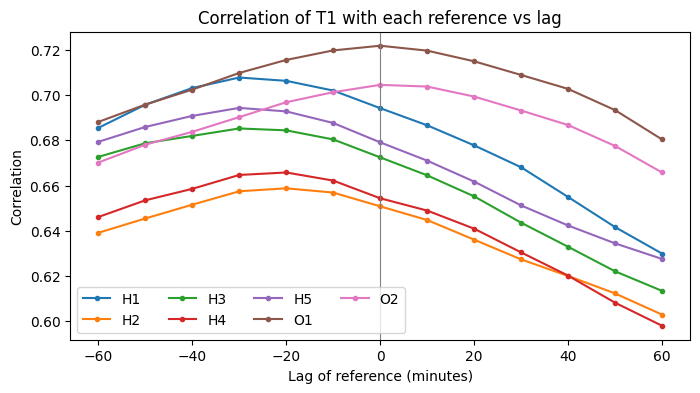

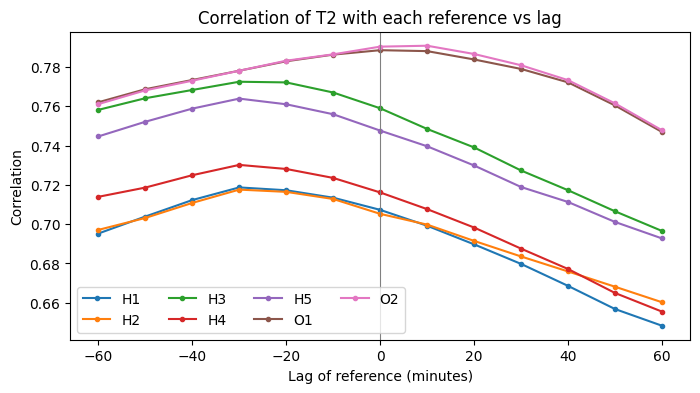

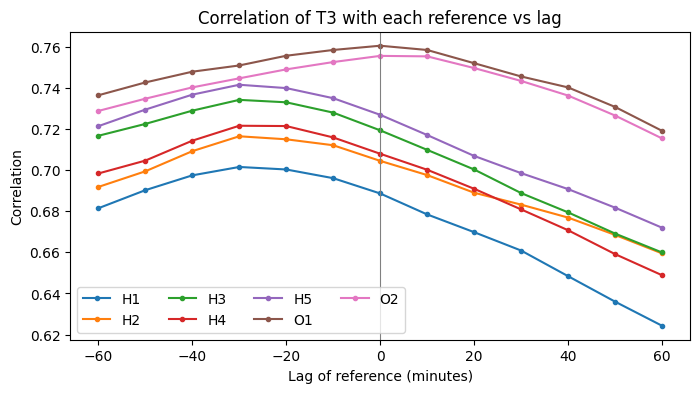

In [13]:
def find_lag(y, x, mask, max_lag=6):
    """Correlation of target y with reference x shifted by -max_lag..+max_lag steps."""
    out = {}
    for L in range(-max_lag, max_lag + 1):
        pair = pd.concat([y, x.shift(L)], axis=1)[mask].dropna()
        out[L * 10] = pair.corr().iloc[0, 1]
    s = pd.Series(out)
    return s.idxmax(), s.max(), s

lag_table, curves = [], {}
for t in targets:
    for r in refs:
        lag_min, c, s = find_lag(ws[t], ws[r], train_dev)
        lag_table.append({"target": t, "ref": r, "lag_min": lag_min, "corr": round(c, 3),
                          "corr_at_0": round(s[0], 3)})
        curves[(t, r)] = s
lag_table = pd.DataFrame(lag_table)

print("Correlation at best lag:")
display(lag_table.pivot(index="ref", columns="target", values="corr"))
print("Best lag (minutes, negative = target sees the wind first):")
display(lag_table.pivot(index="ref", columns="target", values="lag_min"))

# Correlation vs lag for one target, all references
t = targets[0]
fig, ax = plt.subplots(figsize=(8, 4))
for r in refs:
    ax.plot(curves[(t, r)].index, curves[(t, r)].values, marker="o", ms=3, label=r)
ax.axvline(0, color="grey", lw=.8)
ax.set_xlabel("Lag of reference (minutes)"); ax.set_ylabel("Correlation")
ax.set_title(f"Correlation of {t} with each reference vs lag"); ax.legend(ncol=4)
plt.show()

t = targets[1]
fig, ax = plt.subplots(figsize=(8, 4))
for r in refs:
    ax.plot(curves[(t, r)].index, curves[(t, r)].values, marker="o", ms=3, label=r)
ax.axvline(0, color="grey", lw=.8)
ax.set_xlabel("Lag of reference (minutes)"); ax.set_ylabel("Correlation")
ax.set_title(f"Correlation of {t} with each reference vs lag"); ax.legend(ncol=4)
plt.show()

t = targets[2]
fig, ax = plt.subplots(figsize=(8, 4))
for r in refs:
    ax.plot(curves[(t, r)].index, curves[(t, r)].values, marker="o", ms=3, label=r)
ax.axvline(0, color="grey", lw=.8)
ax.set_xlabel("Lag of reference (minutes)"); ax.set_ylabel("Correlation")
ax.set_title(f"Correlation of {t} with each reference vs lag"); ax.legend(ncol=4)
plt.show()

Park O1 and O2 gievs the highest correlation and could be good signal. And for H park, like around 30 minutes later's data seems to have good correlation

## Power Curve

[   0.  584. 1887. 4500.    0.   nan]
Energy of 1 hour at 8 m/s: 2527.0 kWh


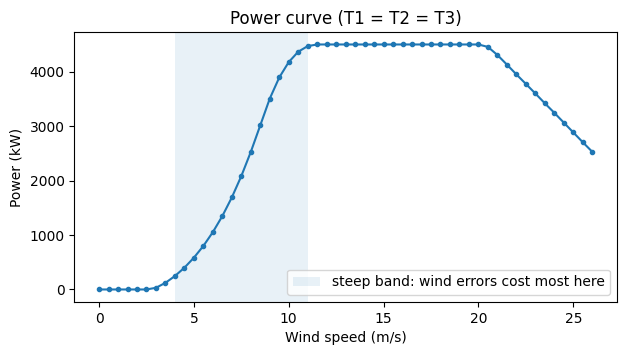

In [14]:
# Power curve: T1 = T2 = T3, so one function for all targets
pc_ws = np.r_[0.0, t1_power["wind_speed"].to_numpy(float)]   # add a 0 m/s -> 0 kW point
pc_kw = np.r_[0.0, t1_power["power"].to_numpy(float)]

def wind_to_power(v):
    """Wind speed (m/s) -> power (kW), linear interpolation between the 0.5 m/s table points."""
    v = np.asarray(v, float)
    p = np.interp(v, pc_ws, pc_kw)
    p[v > pc_ws[-1]] = 0.0          # beyond 26 m/s: turbine off
    p[np.isnan(v)] = np.nan         # missing wind stays missing
    return p

def energy_kwh(v):
    """Energy (kWh) of a series of 10-min wind speeds: power x 1/6 h, summed."""
    return np.nansum(wind_to_power(v)) / 6

# Sanity check
print(wind_to_power([2.0, 5.0, 7.25, 11.5, 30, np.nan]))
print("Energy of 1 hour at 8 m/s:", energy_kwh([8.0] * 6), "kWh")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(pc_ws, pc_kw, marker="o", ms=3)
ax.axvspan(4, 11, alpha=.1, label="steep band: wind errors cost most here")
ax.set_xlabel("Wind speed (m/s)"); ax.set_ylabel("Power (kW)")
ax.set_title("Power curve (T1 = T2 = T3)"); ax.legend()
plt.show()

## Reference Model

Testing out multiple simple baseline regression methods:
Use feature:
- single wind turbine
- OR all wind turbine
- OR the mean

### Evaluation metrics

Notation: $y_t$ = measured wind speed of the target at 10-min step $t$, $\hat{y}_t$ = predicted wind speed,
$P(\cdot)$ = power curve (kW), $N$ = number of evaluated steps.

**Wind speed RMSE** (m/s): typical size of the error at each step; large errors count extra because they are squared.

$$\text{RMSE}_{ws} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}\left(\hat{y}_t - y_t\right)^2}$$

**Wind speed MAE** (m/s): average absolute error at each step.

$$\text{MAE}_{ws} = \frac{1}{N}\sum_{t=1}^{N}\left|\hat{y}_t - y_t\right|$$

**Power RMSE** (kW): same as wind RMSE, but after converting both series through the power curve.
Errors in the steep part of the curve (about 4–11 m/s) weigh most.

$$\text{RMSE}_{P} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}\left(P(\hat{y}_t) - P(y_t)\right)^2}$$

**Energy deviation** (kWh): error in the **total** energy over the whole period. This is the number the loss claim is based on.

$$\text{Energy deviation} = {E_{pred} - E_{true}}$$

**How they differ**

| | RMSE / MAE | Energy deviation |
|---|---|---|
| Compares | Each 10-min step individually | Totals over the whole period |
| Errors cancel? | No: every error counts, regardless of sign | Yes: over- and under-predictions cancel out |
| Sign | Always ≥ 0 | Negative = energy underestimated, positive = overestimated |
| Detects | How close the prediction tracks the real series | Systematic bias in the total, e.g. too-smooth predictions |

A model can have a low RMSE and still a clear energy deviation: regression predictions are smoother than reality,
and because the power curve is convex in the main operating range, smoothed wind gives too little total energy.
Both are graded, so both are reported.

In [15]:
from sklearn.linear_model import LinearRegression

def shifted_ref(t, r):
    """Reference r, shifted by its best lag for target t (from Step 5)."""
    L = int(lag_table.query("target == @t and ref == @r")["lag_min"].iloc[0] // 10)
    return ws[r].shift(L)

def park_mean(t, members):
    """Average of several references (each lag-shifted), scaled to a common level first."""
    S = pd.DataFrame({r: shifted_ref(t, r) for r in members})
    m = S[train_dev].mean()
    return (S / m * m.mean()).mean(axis=1)

# 3-day blocks over the training period
train_days = full_idx[train_dev].normalize().unique()
blocks = [train_days[i:i + 3] for i in range(0, len(train_days), 3)]
block_id = pd.Series(-1, index=full_idx)
for b, days in enumerate(blocks):
    block_id[full_idx.normalize().isin(days) & train_dev] = b
print(len(blocks), "blocks of 3 days")

def evaluate(X, y):
    """Leave-one-3-day-block-out linear regression; metrics over all blocks."""
    X = X.to_frame() if isinstance(X, pd.Series) else X
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression().fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "p_rmse": np.sqrt(((wind_to_power(yp) - wind_to_power(yt)) ** 2).mean()),
            "energy_dev_kwh": e_pred - e_true}

h_park = [r for r in refs if r.startswith("H")]
o_park = [r for r in refs if r.startswith("O")]

results = []
for t in targets:
    y = ws[t]
    setups = {f"single {r}": shifted_ref(t, r) for r in refs}
    setups["O park mean"] = park_mean(t, o_park)
    setups["H park mean"] = park_mean(t, h_park)
    setups["all 7 mean"] = park_mean(t, refs)
    setups["all 7 separately"] = pd.DataFrame({r: shifted_ref(t, r) for r in refs})
    for name, X in setups.items():
        results.append({"target": t, "setup": name, **evaluate(X, y)})
results = pd.DataFrame(results)

print("Wind speed RMSE (m/s), lower is better:")
display(results.pivot(index="setup", columns="target", values="ws_rmse").round(3).sort_values(targets[0]))
print("Energy deviation (kWh), closer to 0 is better:")
display(results.pivot(index="setup", columns="target", values="energy_dev_kwh").round(0))

28 blocks of 3 days
Wind speed RMSE (m/s), lower is better:


target,T1,T2,T3
setup,,,
all 7 separately,1.294,1.121,1.121
all 7 mean,1.358,1.204,1.178
H park mean,1.453,1.363,1.297
single O1,1.460,1.341,1.301
O park mean,1.467,1.307,1.293
single H1,1.480,1.515,1.426
single O2,1.497,1.335,1.313
single H5,1.518,1.411,1.348
single H3,1.537,1.388,1.365


Energy deviation (kWh), closer to 0 is better:


target,T1,T2,T3
setup,,,
H park mean,-244230.0,-210588.0,-201018.0
O park mean,-250798.0,-195984.0,-200863.0
all 7 mean,-206173.0,-155919.0,-160344.0
all 7 separately,-193894.0,-133539.0,-148290.0
single H1,-260125.0,-265744.0,-247575.0
single H2,-297275.0,-269394.0,-235548.0
single H3,-274584.0,-211553.0,-221271.0
single H4,-295006.0,-261540.0,-235670.0
single H5,-268918.0,-218618.0,-216105.0


In [16]:
for t in targets:
    X = pd.DataFrame({r: shifted_ref(t, r) for r in refs})
    ok = X.notna().all(axis=1) & ws[t].notna() & train_dev
    m = LinearRegression().fit(X[ok], ws[t][ok])
    print(t, "intercept", round(m.intercept_, 2), "| weights:",
          dict(zip(refs, m.coef_.round(3))))

T1 intercept 0.54 | weights: {'H1': np.float64(0.277), 'H2': np.float64(0.094), 'H3': np.float64(-0.021), 'H4': np.float64(0.006), 'H5': np.float64(0.09), 'O1': np.float64(0.415), 'O2': np.float64(-0.057)}
T2 intercept 0.47 | weights: {'H1': np.float64(-0.018), 'H2': np.float64(0.048), 'H3': np.float64(0.149), 'H4': np.float64(0.055), 'H5': np.float64(0.193), 'O1': np.float64(0.196), 'O2': np.float64(0.22)}
T3 intercept 0.62 | weights: {'H1': np.float64(-0.022), 'H2': np.float64(0.128), 'H3': np.float64(-0.001), 'H4': np.float64(0.135), 'H5': np.float64(0.183), 'O1': np.float64(0.26), 'O2': np.float64(0.09)}


Some feature contribute nearly nothign , when it is close to 0, maybe we could see if it improves prediction results by removing them

In [17]:
def cv_rmse(t, members, positive=True):
    X = pd.DataFrame({r: shifted_ref(t, r) for r in members})
    y = ws[t]
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression(positive=positive).fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    return np.sqrt(((np.clip(pred[ev], 0, None) - y[ev]) ** 2).mean())

def backward_eliminate(t, members, tol=0.002):
    """Drop references one at a time while CV RMSE gets no worse than +tol m/s."""
    current = list(members)
    best = cv_rmse(t, current)
    history = [{"removed": "-", "refs": len(current), "cv_rmse": best}]
    while len(current) > 1:
        trials = {r: cv_rmse(t, [m for m in current if m != r]) for r in current}
        r_drop = min(trials, key=trials.get)
        if trials[r_drop] > best + tol:
            break
        current.remove(r_drop)
        best = min(best, trials[r_drop])
        history.append({"removed": r_drop, "refs": len(current), "cv_rmse": trials[r_drop]})
    return current, pd.DataFrame(history)

chosen_refs = {}
for t in targets:
    kept, hist = backward_eliminate(t, refs)
    chosen_refs[t] = kept
    print(f"\n{t}: keep {kept}")
    display(hist.round(4))


T1: keep ['H1', 'H2', 'O1']


,removed,refs,cv_rmse
0,-,7,1.2905
1,H3,6,1.2895
2,H4,5,1.2887
3,H5,4,1.2883
4,O2,3,1.2883



T2: keep ['H1', 'H3', 'H5', 'O1', 'O2']


,removed,refs,cv_rmse
0,-,7,1.1197
1,H2,6,1.1193
2,H4,5,1.1203



T3: keep ['H1', 'H2', 'H4', 'H5', 'O1']


,removed,refs,cv_rmse
0,-,7,1.1196
1,H3,6,1.1189
2,O2,5,1.1198


### Use a smoothed wind speed reading as feature to eliminate noise in terms of gusts

Wind RMSE (m/s) by smoothing window:


target,T1,T2,T3
window_min,,,
10,1.288,1.120,1.120
30,1.269,1.102,1.099
60,1.255,1.089,1.087
120,1.248,1.085,1.080
180,1.253,1.094,1.085
360,1.285,1.137,1.120


Energy deviation (kWh) by smoothing window:


target,T1,T2,T3
window_min,,,
10,-191230.0,-130442.0,-146687.0
30,-183587.0,-122361.0,-139259.0
60,-177450.0,-115762.0,-133922.0
120,-172300.0,-110084.0,-128945.0
180,-172096.0,-109031.0,-128227.0
360,-180612.0,-117286.0,-136704.0


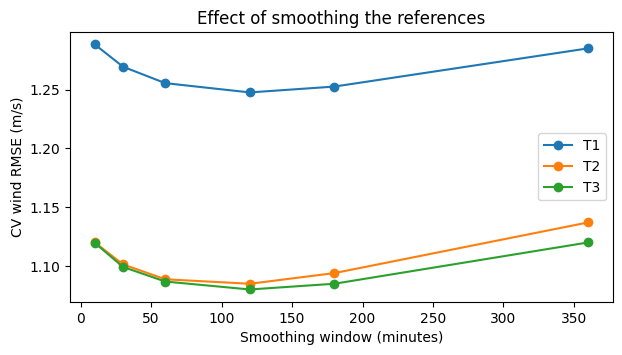

,window_min,ws_rmse,ws_mae,energy_dev_kwh
target,,,,
T1,120,1.247611,0.938909,-172299.676356
T2,120,1.085145,0.824514,-110083.581543
T3,120,1.080307,0.818250,-128944.747972


In [18]:
def smoothed_ref(t, r, window):
    """Lag-shifted reference, smoothed with a centred rolling mean of `window` steps (10 min each)."""
    x = shifted_ref(t, r)
    if window > 1:
        x = x.rolling(window, center=True, min_periods=window // 2 + 1).mean()
    return x

def cv_eval(t, members, window, positive=True):
    """Leave-one-3-day-block-out regression on smoothed references."""
    X = pd.DataFrame({r: smoothed_ref(t, r, window) for r in members})
    y = ws[t]                                   # target is NOT smoothed: we predict the real 10-min values
    ok = X.notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = LinearRegression(positive=positive).fit(X[fit], y[fit])
        pred[test] = m.predict(X[test])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "energy_dev_kwh": e_pred - e_true}

windows = [1, 3, 6, 12, 18, 36]      # steps: 1 = no smoothing ... 36 = ~6 h
rows = []
for t in targets:
    for w in windows:
        rows.append({"target": t, "window_min": w * 10, **cv_eval(t, chosen_refs[t], w)})
smooth_res = pd.DataFrame(rows)

print("Wind RMSE (m/s) by smoothing window:")
display(smooth_res.pivot(index="window_min", columns="target", values="ws_rmse").round(3))
print("Energy deviation (kWh) by smoothing window:")
display(smooth_res.pivot(index="window_min", columns="target", values="energy_dev_kwh").round(0))

# Plot RMSE vs window
fig, ax = plt.subplots(figsize=(7, 3.5))
for t in targets:
    s = smooth_res[smooth_res.target == t]
    ax.plot(s.window_min, s.ws_rmse, marker="o", label=t)
ax.set_xlabel("Smoothing window (minutes)"); ax.set_ylabel("CV wind RMSE (m/s)")
ax.set_title("Effect of smoothing the references"); ax.legend()
plt.show()

# Best window per target
best_window = smooth_res.loc[smooth_res.groupby("target")["ws_rmse"].idxmin()].set_index("target")
display(best_window)

## could we improve the modelling with T turines weather data

### Given T turbines also not have weather data sometimes, could we use other ones to help

In [19]:
temp = wide["ambient_temperature"]
pres = wide["air_pressure"]          # O1/O2 are NaN: placeholder removed in cleaning
m = train_dev

# 1. How similar are the parks' temperature and pressure?
print("Temperature correlation (train period):")
display(temp[m].corr().loc[targets, refs].round(3))
print("Air pressure correlation (train period, O park has no real pressure):")
display(pres[m].corr().loc[targets, [r for r in refs if r.startswith("H")]].round(3))

# Level differences: pressure offset hints at altitude difference (~8 m per hPa near the ground)
lvl = pd.DataFrame({"mean temp (°C)": temp[m].mean(), "mean pressure (hPa)": pres[m].mean()})
display(lvl.round(2))

# 2. Can a reference park stand in for T? Error when using the H-park average as T's value
h_park = [r for r in refs if r.startswith("H")]
for t in targets:
    for name, s, unit in [("temperature", temp, "°C"), ("pressure", pres, "hPa")]:
        proxy = s[h_park].mean(axis=1)
        d = (s[t] - proxy)[m].dropna()
        print(f"{t} {name}: mean offset {d.mean():+.2f} {unit}, std of difference {d.std():.2f} {unit}")

# 3. Do reference temperature/pressure explain what the current wind model misses?
def model_residuals(t, window=7):
    X = pd.DataFrame({r: smoothed_ref(t, r, window) for r in chosen_refs[t]})
    ok = X.notna().all(axis=1) & ws[t].notna() & m
    reg = LinearRegression(positive=True).fit(X[ok], ws[t][ok])
    pred = pd.Series(np.nan, index=full_idx)
    pred[X.notna().all(axis=1)] = reg.predict(X[X.notna().all(axis=1)])
    return ws[t] - pred

h_temp = temp[h_park].mean(axis=1)
h_pres = pres[h_park].mean(axis=1)
h_turb = wide["wind_speed_stddev"][h_park].mean(axis=1)
air_density = h_pres * 100 / (287.05 * (h_temp + 273.15))
cand = pd.DataFrame({"ref temperature": h_temp, "ref pressure": h_pres,
                     "air density": air_density, "ref turbulence": h_turb,
                     "temp change 3h": h_temp.diff(18),          # warming/cooling ~ day/night stability
                     "pressure change 3h": h_pres.diff(18)})     # passing weather systems

res_corr = pd.DataFrame({t: cand[m].corrwith(model_residuals(t)[m]) for t in targets}).round(3)
print("Correlation with the current model's wind error (residual), per target:")
display(res_corr)

Temperature correlation (train period):


,H1,H2,H3,H4,H5,O1,O2
T1,0.982,0.981,0.978,0.981,0.978,0.978,0.974
T2,0.980,0.979,0.976,0.979,0.976,0.978,0.975
T3,0.981,0.981,0.977,0.981,0.977,0.977,0.974


Air pressure correlation (train period, O park has no real pressure):


,H1,H2,H3,H4,H5
T1,0.981,0.986,0.986,0.989,0.987
T2,0.987,0.993,0.988,0.992,0.994
T3,0.982,0.988,0.990,0.992,0.990


,mean temp (°C),mean pressure (hPa)
H1,18.61,990.72
H2,18.45,988.68
H3,18.64,986.01
H4,18.39,990.32
H5,18.64,985.73
O1,18.84,NaN
O2,18.14,NaN
T1,19.19,998.00
T2,19.45,998.82
T3,19.32,1000.09


T1 temperature: mean offset +0.64 °C, std of difference 0.84 °C
T1 pressure: mean offset +9.72 hPa, std of difference 0.79 hPa
T2 temperature: mean offset +0.92 °C, std of difference 0.90 °C
T2 pressure: mean offset +10.53 hPa, std of difference 0.57 hPa
T3 temperature: mean offset +0.77 °C, std of difference 0.85 °C
T3 pressure: mean offset +11.81 hPa, std of difference 0.69 hPa
Correlation with the current model's wind error (residual), per target:


,T1,T2,T3
ref temperature,0.089,0.024,0.017
ref pressure,0.077,-0.030,-0.015
air density,-0.054,-0.031,-0.020
ref turbulence,0.024,0.101,0.063
temp change 3h,-0.017,0.109,0.063
pressure change 3h,0.000,-0.075,-0.044


### Forward Selection to select the features

In [20]:
from scipy.optimize import lsq_linear

WINDOW = 13                      # 130 min, centred (odd number of steps keeps it symmetric)
h_park = [r for r in refs if r.startswith("H")]

class BoundedLinear:
    """Linear regression where reference weights are >= 0 and all other coefficients are free."""
    def __init__(self, nonneg_cols):
        self.nonneg_cols = set(nonneg_cols)
    def fit(self, X, y):
        self.cols = list(X.columns)
        A = np.column_stack([np.ones(len(X)), X.values])
        lb = [-np.inf] + [0 if c in self.nonneg_cols else -np.inf for c in self.cols]
        sol = lsq_linear(A, y.values, bounds=(lb, [np.inf] * len(lb)))
        self.intercept_, self.coef_ = sol.x[0], sol.x[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X[self.cols].values @ self.coef_

def build_features(t, window=WINDOW):
    F = pd.DataFrame(index=full_idx)
    for r in chosen_refs[t]:
        F[f"ws_{r}"] = smoothed_ref(t, r, window)
    ref_cols = [f"ws_{r}" for r in chosen_refs[t]]
    ref_avg = F[ref_cols].mean(axis=1)
    hour = full_idx.hour + full_idx.minute / 60
    F["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    F["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    F["ref_x_hour_sin"] = ref_avg * F["hour_sin"]          # slope changes with time of day
    F["ref_x_hour_cos"] = ref_avg * F["hour_cos"]
    rad = np.deg2rad(wide["wind_direction"][refs])
    F["dir_sin"] = np.sin(rad).mean(axis=1)
    F["dir_cos"] = np.cos(rad).mean(axis=1)
    F["ref_x_dir_sin"] = ref_avg * F["dir_sin"]            # slope changes with wind direction
    F["ref_x_dir_cos"] = ref_avg * F["dir_cos"]
    F["turbulence"] = wide["wind_speed_stddev"][h_park].mean(axis=1).rolling(window, center=True, min_periods=1).mean()
    F["temp_change_3h"] = wide["ambient_temperature"][h_park].mean(axis=1).diff(18)
    return F, ref_cols

def cv_score(t, F, cols, ref_cols):
    y = ws[t]
    ok = F[cols].notna().all(axis=1) & y.notna()
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ok
        fit = train_dev & ok & (block_id != b)
        if test.sum() == 0:
            continue
        m = BoundedLinear(ref_cols).fit(F.loc[fit, cols], y[fit])
        pred[test] = m.predict(F.loc[test, cols])
    ev = pred.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "energy_dev_kwh": e_pred - e_true}

candidates = {
    "hour":           ["hour_sin", "hour_cos"],
    "ref_x_hour":     ["ref_x_hour_sin", "ref_x_hour_cos"],
    "direction":      ["dir_sin", "dir_cos"],
    "ref_x_dir":      ["ref_x_dir_sin", "ref_x_dir_cos"],
    "turbulence":     ["turbulence"],
    "temp_change_3h": ["temp_change_3h"],
}

def forward_select(t, min_gain=0.002):
    F, ref_cols = build_features(t)
    cols, remaining = list(ref_cols), dict(candidates)
    best = cv_score(t, F, cols, ref_cols)
    history = [{"step": 0, "added": "references only", **best}]
    while remaining:
        trials = {g: cv_score(t, F, cols + c, ref_cols) for g, c in remaining.items()}
        g = min(trials, key=lambda k: trials[k]["ws_rmse"])
        gain = (best["ws_rmse"] - trials[g]["ws_rmse"]) / best["ws_rmse"]
        print(f"  {t} step {len(history)}: " + ", ".join(
            f"{k}={v['ws_rmse']:.3f}" for k, v in sorted(trials.items(), key=lambda kv: kv[1]["ws_rmse"])))
        if gain < min_gain:
            print(f"  stop: best gain {gain * 100:.2f}% < {min_gain * 100:.1f}%")
            break
        cols += remaining.pop(g)
        best = trials[g]
        history.append({"step": len(history), "added": g, **best})
    return cols, ref_cols, pd.DataFrame(history).set_index("step")

selected = {}
for t in targets:
    print(f"\n===== {t} =====")
    cols, ref_cols, hist = forward_select(t)
    selected[t] = (cols, ref_cols)
    display(hist.round(3))


===== T1 =====
  T1 step 1: ref_x_dir=1.205, direction=1.209, ref_x_hour=1.243, hour=1.245, temp_change_3h=1.247, turbulence=1.250
  T1 step 2: ref_x_hour=1.201, turbulence=1.202, hour=1.203, temp_change_3h=1.204, direction=1.206
  T1 step 3: temp_change_3h=1.200, hour=1.201, turbulence=1.201, direction=1.203
  stop: best gain 0.08% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_kwh
step,,,,
0,references only,1.247,0.939,-171819.194
1,ref_x_dir,1.205,0.905,-151859.452
2,ref_x_hour,1.201,0.901,-150026.380



===== T2 =====
  T2 step 1: turbulence=1.069, ref_x_hour=1.074, temp_change_3h=1.074, hour=1.078, ref_x_dir=1.082, direction=1.085
  T2 step 2: temp_change_3h=1.065, ref_x_hour=1.069, ref_x_dir=1.069, direction=1.069, hour=1.070
  T2 step 3: ref_x_hour=1.067, direction=1.067, ref_x_dir=1.067, hour=1.068
  stop: best gain -0.17% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_kwh
step,,,,
0,references only,1.083,0.823,-109087.875
1,turbulence,1.069,0.809,-110956.486
2,temp_change_3h,1.065,0.805,-109166.016



===== T3 =====
  T3 step 1: turbulence=1.073, temp_change_3h=1.076, ref_x_hour=1.076, hour=1.079, direction=1.082, ref_x_dir=1.083
  T3 step 2: temp_change_3h=1.071, ref_x_hour=1.074, hour=1.074, direction=1.074, ref_x_dir=1.076
  stop: best gain 0.19% < 0.2%


,added,ws_rmse,ws_mae,energy_dev_kwh
step,,,,
0,references only,1.080,0.817,-128402.731
1,turbulence,1.073,0.810,-126186.851


## Summary SO Far

In [21]:
def cv_predict(t, predict_block):
    """Run any predictor over the 3-day CV blocks. predict_block(fit_mask, test_mask) -> Series."""
    pred = pd.Series(np.nan, index=full_idx)
    for b in range(len(blocks)):
        test = (block_id == b) & ws[t].notna()
        if test.sum() == 0:
            continue
        fit = train_dev & (block_id != b)
        pred[test] = predict_block(fit, test)[test]
    return pred

def metrics(t, pred):
    y = ws[t]
    ev = pred.notna() & y.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    e_true, e_pred = wind_to_power(yt).sum() / 6, wind_to_power(yp).sum() / 6
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "ws_mae": np.abs(yp - yt).mean(),
            "p_rmse": np.sqrt(((wind_to_power(yp) - wind_to_power(yt)) ** 2).mean()),
            "energy_dev_kwh": e_pred - e_true,
            "n": int(ev.sum())}

def baseline_mean(t):
    return cv_predict(t, lambda fit, test: pd.Series(ws[t][fit].mean(), index=full_idx))

def baseline_hourly_mean(t):
    hour = pd.Series(full_idx.hour, index=full_idx)
    def f(fit, test):
        return hour.map(ws[t][fit].groupby(hour[fit]).mean())
    return cv_predict(t, f)

def baseline_interpolation(t):
    def f(fit, test):
        y = ws[t].copy()
        y[test] = np.nan
        return y.interpolate(method="time", limit_area="inside")
    return cv_predict(t, f)

def baseline_raw_refs(t):
    raw = ws[refs].mean(axis=1)
    return cv_predict(t, lambda fit, test: raw)

def model_regression(t, X, nonneg_cols=None):
    """Bounded linear regression on feature table X (reference weights >= 0)."""
    nonneg = list(X.columns) if nonneg_cols is None else nonneg_cols
    def f(fit, test):
        ok = fit & X.notna().all(axis=1) & ws[t].notna()
        reg = BoundedLinear(nonneg).fit(X.loc[ok], ws[t][ok])
        out = pd.Series(np.nan, index=full_idx)
        has = X.notna().all(axis=1)
        out[has] = reg.predict(X.loc[has])
        return out
    return cv_predict(t, f)

rows = []
for t in targets:
    best_single = lag_table.query("target == @t").sort_values("corr").iloc[-1]["ref"]
    F, ref_cols = build_features(t)
    sel_cols, sel_refs = selected[t]
    setups = {
        "A. Always the mean of T":               baseline_mean(t),
        "B. Mean of T for that hour of day":     baseline_hourly_mean(t),
        "C. Straight line across the gap":       baseline_interpolation(t),
        "D. Raw reference average (no model)":   baseline_raw_refs(t),
        "E. Regression, best single reference":  model_regression(t, pd.DataFrame({best_single: shifted_ref(t, best_single)})),
        "F. Regression, chosen refs, smoothed":  model_regression(t, F[ref_cols]),
        "G. + selected extra features":          model_regression(t, F[sel_cols], nonneg_cols=sel_refs),
    }
    for name, pred in setups.items():
        rows.append({"target": t, "setup": name, **metrics(t, pred)})
compare = pd.DataFrame(rows)

for col, label, d in [("ws_rmse", "Wind RMSE (m/s)", 3), ("p_rmse", "Power RMSE (kW)", 0),
                      ("energy_dev_kwh", "Energy deviation (kWh)", 0)]:
    print(label)
    display(compare.pivot(index="setup", columns="target", values=col).round(d))

ref_rmse = compare[compare.setup.str.startswith("A.")].set_index("target")["ws_rmse"]
compare["error_reduction_vs_mean_%"] = (1 - compare["ws_rmse"] / compare["target"].map(ref_rmse)) * 100
print("Wind RMSE reduction vs. always predicting the mean (%):")
display(compare.pivot(index="setup", columns="target", values="error_reduction_vs_mean_%").round(0))

Wind RMSE (m/s)


target,T1,T2,T3
setup,,,
A. Always the mean of T,2.114,2.192,2.014
B. Mean of T for that hour of day,2.069,2.171,1.993
C. Straight line across the gap,2.309,2.230,2.151
D. Raw reference average (no model),1.588,1.312,1.455
"E. Regression, best single reference",1.460,1.335,1.301
"F. Regression, chosen refs, smoothed",1.247,1.083,1.080
G. + selected extra features,1.201,1.065,1.073


Power RMSE (kW)


target,T1,T2,T3
setup,,,
A. Always the mean of T,1128.0,1190.0,1040.0
B. Mean of T for that hour of day,1108.0,1181.0,1035.0
C. Straight line across the gap,1161.0,1115.0,1027.0
D. Raw reference average (no model),915.0,763.0,854.0
"E. Regression, best single reference",825.0,777.0,725.0
"F. Regression, chosen refs, smoothed",727.0,646.0,620.0
G. + selected extra features,696.0,630.0,613.0


Energy deviation (kWh)


target,T1,T2,T3
setup,,,
A. Always the mean of T,-562474.0,-617233.0,-516245.0
B. Mean of T for that hour of day,-531735.0,-592088.0,-502773.0
C. Straight line across the gap,-118007.0,-195422.0,-171149.0
D. Raw reference average (no model),582627.0,307960.0,680241.0
"E. Regression, best single reference",-246441.0,-209469.0,-202198.0
"F. Regression, chosen refs, smoothed",-171819.0,-109088.0,-128403.0
G. + selected extra features,-150026.0,-109166.0,-126187.0


Wind RMSE reduction vs. always predicting the mean (%):


target,T1,T2,T3
setup,,,
A. Always the mean of T,0.0,0.0,0.0
B. Mean of T for that hour of day,2.0,1.0,1.0
C. Straight line across the gap,-9.0,-2.0,-7.0
D. Raw reference average (no model),25.0,40.0,28.0
"E. Regression, best single reference",31.0,39.0,35.0
"F. Regression, chosen refs, smoothed",41.0,51.0,46.0
G. + selected extra features,43.0,51.0,47.0


## Experiment: weight training errors by the power-curve slope
A 1 m/s wind error costs almost no power below cut-in or at rated power, and the most on the steep part (~6–11 m/s).
Each training row gets the weight `w = floor + (1 - floor) * |P'(v)| / max P'`, where
- `P'(v)` = slope of the power curve at wind speed `v` (kW per m/s)
- `v` = prediction of a first, unweighted fit (so the weights never look at the answer)

`floor = 1` means unweighted (model G), `floor = 0` means only the steep part counts.
Energy uses expected power (the power curve averaged over the error spread), the same as `src/`.

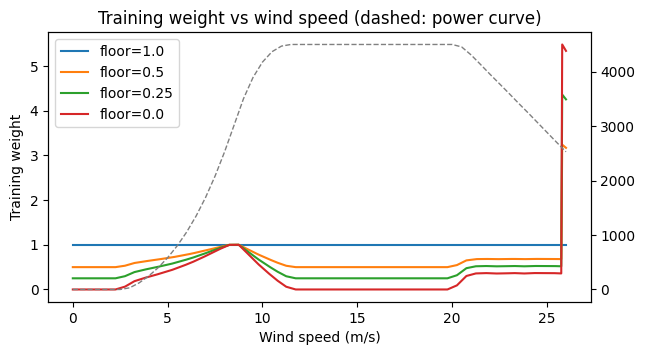

In [22]:
pc_grid = np.arange(0, 26.01, 0.05)

def pc_slope(v, h=0.25):
    """dP/dv (kW per m/s), central difference."""
    v = np.asarray(v, float)
    return (wind_to_power(v + h) - wind_to_power(np.clip(v - h, 0, None))) / (2 * h)

pc_slope_max = np.nanmax(pc_slope(pc_grid))

def slope_weight(v, floor):
    """abs(): the curve derates above 20 m/s, so the slope turns negative there."""
    return floor + (1 - floor) * np.abs(np.nan_to_num(pc_slope(v))) / pc_slope_max

def expected_power(ws_pred, residuals, n=41):
    """Power averaged over the error distribution instead of P(point prediction)."""
    r = np.quantile(residuals, (np.arange(n) + 0.5) / n)
    samples = np.clip(np.asarray(ws_pred, float)[:, None] + r, 0, None)
    return wind_to_power(samples.ravel()).reshape(samples.shape).mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
for floor in [1.0, 0.5, 0.25, 0.0]:
    ax.plot(pc_grid, slope_weight(pc_grid, floor), label=f"floor={floor}")
ax.twinx().plot(pc_ws, pc_kw, color="grey", ls="--", lw=1)
ax.set_xlabel("Wind speed (m/s)"); ax.set_ylabel("Training weight")
ax.set_title("Training weight vs wind speed (dashed: power curve)"); ax.legend()
plt.show()

In [38]:
class WeightedBoundedLinear(BoundedLinear):
    """BoundedLinear that minimises sum(w * error^2)."""
    def fit(self, X, y, w=None):
        self.cols = list(X.columns)
        sw = np.ones(len(X)) if w is None else np.sqrt(w)
        A = np.column_stack([np.ones(len(X)), X.values]) * sw[:, None]
        lb = [-np.inf] + [0 if c in self.nonneg_cols else -np.inf for c in self.cols]
        sol = lsq_linear(A, y.values * sw, bounds=(lb, [np.inf] * len(lb)))
        self.intercept_, self.coef_ = sol.x[0], sol.x[1:]
        return self

def weighted_predictor(t, X, nonneg_cols, floor=1.0):
    """predict_block(fit, test) for cv_predict."""
    has = X.notna().all(axis=1)
    def f(fit, test):
        ok = fit & has & ws[t].notna()
        Xf, yf = X.loc[ok], ws[t][ok]
        w = None
        if floor < 1:
            first = WeightedBoundedLinear(nonneg_cols).fit(Xf, yf).predict(Xf)
            w = slope_weight(first, floor)
        reg = WeightedBoundedLinear(nonneg_cols).fit(Xf, yf, w)
        out = pd.Series(np.nan, index=full_idx)
        out[has] = reg.predict(X.loc[has])
        return out
    return f

def score(t, pred, mask=True):
    y = ws[t]
    ev = pred.notna() & y.notna() & mask
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    pt, pe = wind_to_power(yt), expected_power(yp, yt - yp)
    pp = wind_to_power(yp)                       # power curve interpolated at the predicted wind
    return {"ws_rmse": np.sqrt(((yp - yt) ** 2).mean()),
            "p_rmse": np.sqrt(((pe - pt) ** 2).mean()),
            "energy_dev_kwh": (pe.sum() - pt.sum()) / 6,
            "p_rmse_point": np.sqrt(((pp - pt) ** 2).mean()),
            "energy_dev_kwh_point": (pp.sum() - pt.sum()) / 6}


In [24]:
WS_BINS   = [0, 3, 6, 9, 11.5, 40]
WS_LABELS = ["0-3 below cut-in", "3-6", "6-9", "9-11.5", "11.5+ rated"]

def region_metrics(t, pred, by="actual"):
    """Errors split by power-curve region.
    by="actual": bin on measured wind (regression to the mean: low bins look over-, high bins under-predicted)
    by="pred":   bin on predicted wind (is the model calibrated for what it predicts?)
    energy_err_kwh adds up over the regions to the total energy deviation (kWh)."""
    y = ws[t]
    ev = pred.notna() & y.notna()
    yt, yp = y[ev].values, np.clip(pred[ev].values, 0, None)
    pt, pe = wind_to_power(yt), expected_power(yp, yt - yp)
    region = pd.cut(yt if by == "actual" else yp, WS_BINS, labels=WS_LABELS, right=False)
    df = pd.DataFrame({"region": region, "err": yp - yt, "perr": pe - pt, "pt": pt, "pe": pe})
    g = df.groupby("region", observed=False)
    e_true = g["pt"].sum()
    return pd.DataFrame({
        "time_%": g.size() / len(df) * 100,
        "energy_%": e_true / df["pt"].sum() * 100,
        "ws_bias": g["err"].mean(),
        "ws_rmse": g["err"].apply(lambda e: np.sqrt((e ** 2).mean())),
        "p_rmse": g["perr"].apply(lambda e: np.sqrt((e ** 2).mean())),
        "energy_err_kwh": (g["pe"].sum() - e_true) / 6,
    })

In [25]:
floors = [1.0, 0.5, 0.25, 0.0]          # 1.0 = unweighted model G
rows, cv_preds = [], {}
for t in targets:
    F, _ = build_features(t)
    sel_cols, sel_refs = selected[t]
    for floor in floors:
        f = weighted_predictor(t, F[sel_cols], sel_refs, floor)
        cv_preds[(t, floor)] = pred = cv_predict(t, f)
        shown_pred = f(pd.Series(train_dev, index=full_idx), None)
        rows.append({"target": t, "floor": floor,
                     **{f"cv_{k}": v for k, v in score(t, pred).items()},
                     **{f"shown_{k}": v for k, v in score(t, shown_pred, shown).items()}})
weighting = pd.DataFrame(rows)

for col in ["cv_ws_rmse", "cv_p_rmse", "cv_energy_dev_kwh", "shown_ws_rmse", "shown_p_rmse", "shown_energy_dev_kwh"]:
    print(col)
    display(weighting.pivot(index="floor", columns="target", values=col).round(3 if "rmse" in col else 0))

cv_ws_rmse


target,T1,T2,T3
floor,,,
0.00,1.205,1.070,1.078
0.25,1.203,1.067,1.075
0.50,1.202,1.066,1.074
1.00,1.201,1.065,1.073


cv_p_rmse


target,T1,T2,T3
floor,,,
0.00,689.100,620.422,604.842
0.25,687.744,620.253,604.638
0.50,686.958,620.416,604.775
1.00,686.043,620.840,605.090


cv_energy_dev_kwh


...

target,T1,T2,T3
floor,,,
0.00,1.481,1.151,1.289
0.25,1.484,1.156,1.289
0.50,1.487,1.159,1.290
1.00,1.490,1.163,1.290


shown_p_rmse


target,T1,T2,T3
floor,,,
0.00,851.879,707.101,802.086
0.25,853.145,710.420,804.298
0.50,853.942,712.703,805.591
1.00,854.933,715.722,807.224


shown_energy_dev_kwh


target,T1,T2,T3
floor,,,
0.00,9410.0,-3145.0,431.0
0.25,9683.0,-2667.0,1177.0
0.50,9824.0,-2397.0,1537.0
1.00,9839.0,-2118.0,2046.0


T1, unweighted, binned on actual wind


,time_%,energy_%,ws_bias,ws_rmse,p_rmse,energy_err_kwh
region,,,,,,
0-3 below cut-in,12.88,0.07,0.76,1.17,297.21,41901.33
3-6,54.53,25.51,0.31,1.02,512.20,262787.68
6-9,27.64,54.33,-0.61,1.23,813.15,-165275.08
9-11.5,4.58,18.41,-1.86,2.16,1641.08,-126687.93
11.5+ rated,0.37,1.67,-3.71,4.23,1646.22,-8597.48


T2, unweighted, binned on actual wind


,time_%,energy_%,ws_bias,ws_rmse,p_rmse,energy_err_kwh
region,,,,,,
0-3 below cut-in,11.99,0.06,0.70,1.02,173.10,27016.25
3-6,48.01,20.41,0.23,0.92,446.93,186578.94
6-9,34.07,58.49,-0.32,1.06,734.38,-96730.91
9-11.5,5.53,19.44,-1.29,1.71,1306.14,-109770.94
11.5+ rated,0.41,1.60,-3.16,3.85,1397.40,-6670.66


T3, unweighted, binned on actual wind


,time_%,energy_%,ws_bias,ws_rmse,p_rmse,energy_err_kwh
region,,,,,,
0-3 below cut-in,12.76,0.07,0.68,0.99,168.18,28698.47
3-6,55.14,27.91,0.23,0.90,428.87,207244.23
6-9,28.22,55.60,-0.51,1.14,767.03,-139259.07
9-11.5,3.56,14.92,-1.62,1.99,1532.26,-88117.77
11.5+ rated,0.32,1.51,-4.23,4.88,1915.55,-8542.82


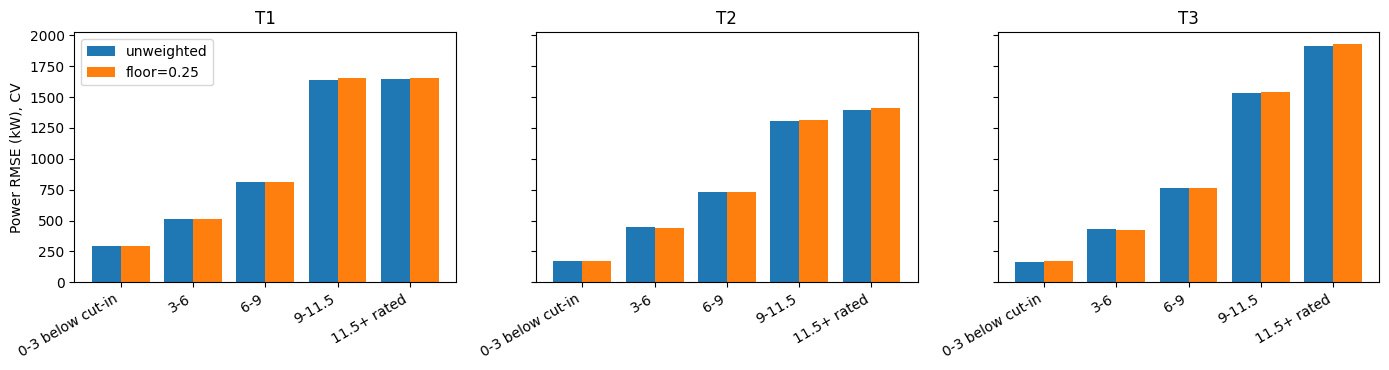

In [26]:
for t in targets:
    for by in ["actual"]:
        print(f"{t}, unweighted, binned on {by} wind")
        display(region_metrics(t, cv_preds[(t, 1.0)], by=by).round(2))

compare = 0.25
fig, axes = plt.subplots(1, len(targets), figsize=(14, 3.8), sharey=True)
x = np.arange(len(WS_LABELS))
for ax, t in zip(axes, targets):
    ax.bar(x - 0.2, region_metrics(t, cv_preds[(t, 1.0)])["p_rmse"], 0.4, label="unweighted")
    ax.bar(x + 0.2, region_metrics(t, cv_preds[(t, compare)])["p_rmse"], 0.4, label=f"floor={compare}")
    ax.set_xticks(x, WS_LABELS, rotation=30, ha="right"); ax.set_title(t)
axes[0].set_ylabel("Power RMSE (kW), CV"); axes[0].legend()
plt.tight_layout(); plt.show()

,train_T1/T2,train_T1_ti,shown_T1/T2,shown_time_%
"(-0.001, 15.0]",0.983,0.187,NaN,0.000
"(15.0, 30.0]",1.046,0.188,NaN,0.000
"(30.0, 45.0]",1.082,0.173,NaN,0.000
"(45.0, 60.0]",1.040,0.121,NaN,0.000
"(60.0, 75.0]",1.146,0.154,0.984,0.133
"(75.0, 90.0]",1.056,0.170,1.025,0.398
"(90.0, 105.0]",1.067,0.133,1.027,0.663
"(105.0, 120.0]",0.971,0.154,0.910,2.785
"(120.0, 135.0]",0.878,0.197,0.575,2.918
"(135.0, 150.0]",0.949,0.177,0.894,5.040


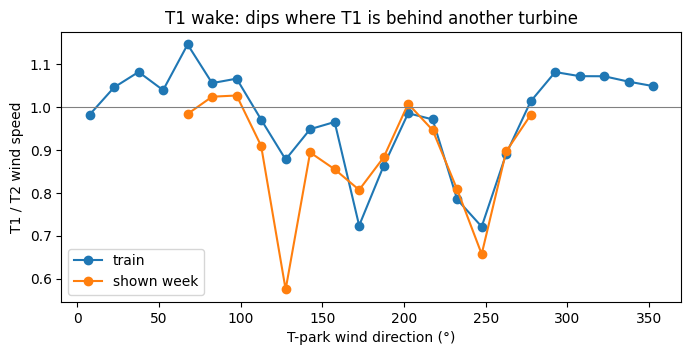

In [27]:
def circmean(df):
    x = np.deg2rad(df)
    return np.rad2deg(np.arctan2(np.sin(x).mean(axis=1), np.cos(x).mean(axis=1))) % 360

dir_T = circmean(wide["wind_direction"][["T2", "T3"]])   # T-park direction: diagnosis only (blanked in the outage)
dir_O = circmean(wide["wind_direction"][["O1", "O2"]])   # O-park direction: available in the outage

ok = ws[["T1", "T2"]].notna().all(axis=1) & (ws["T2"] > 4)
ratio = ws["T1"] / ws["T2"]
ti_T1 = wide["wind_speed_stddev"]["T1"] / ws["T1"]
sector = pd.cut(dir_T, np.arange(0, 361, 15), include_lowest=True)

wake = pd.DataFrame({
    "train_T1/T2": ratio[ok & train_dev].groupby(sector[ok & train_dev], observed=False).median(),
    "train_T1_ti": ti_T1[ok & train_dev].groupby(sector[ok & train_dev], observed=False).median(),
    "shown_T1/T2": ratio[ok & shown].groupby(sector[ok & shown], observed=False).median(),
    "shown_time_%": sector[ok & shown].value_counts(normalize=True).sort_index() * 100,
})
display(wake.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
mid = np.arange(7.5, 360, 15)
ax.plot(mid, wake["train_T1/T2"], marker="o", label="train")
ax.plot(mid, wake["shown_T1/T2"], marker="o", label="shown week")
ax.axhline(1, color="grey", lw=0.8)
ax.set_xlabel("T-park wind direction (°)"); ax.set_ylabel("T1 / T2 wind speed")
ax.set_title("T1 wake: dips where T1 is behind another turbine"); ax.legend()
plt.show()


In [28]:
def dir_harmonics(t, ks=(2, 3, 4)):
    """Model G features + ref_avg * sin/cos(k * O-park direction): a smooth direction correction curve."""
    F, _ = build_features(t)
    sel_cols, sel_refs = selected[t]
    X = F[sel_cols].copy()
    ref_avg = F[sel_refs].mean(axis=1)
    th = np.deg2rad(dir_O)
    for k in ks:
        X[f"ref_x_sin{k}"] = ref_avg * np.sin(k * th)
        X[f"ref_x_cos{k}"] = ref_avg * np.cos(k * th)
    return X, sel_refs

rows = []
for t in targets:
    for name, ks in [("model G", ()), ("+ direction harmonics 2-4", (2, 3, 4))]:
        X, nonneg = dir_harmonics(t, ks)
        f = weighted_predictor(t, X, nonneg)
        cv = cv_predict(t, f)
        sh = f(pd.Series(train_dev, index=full_idx), None)
        rows.append({"target": t, "setup": name,
                     **{f"cv_{k}": v for k, v in score(t, cv).items()},
                     **{f"shown_{k}": v for k, v in score(t, sh, shown).items()},
                     "shown_bias": (sh - ws[t])[shown].mean()})
harm = pd.DataFrame(rows)
for col in ["cv_ws_rmse", "cv_p_rmse", "cv_energy_dev_kwh", "shown_ws_rmse", "shown_p_rmse", "shown_energy_dev_kwh", "shown_bias"]:
    print(col)
    display(harm.pivot(index="setup", columns="target", values=col).round(3 if "rmse" in col or "bias" in col else 0))


cv_ws_rmse


target,T1,T2,T3
setup,,,
+ direction harmonics 2-4,1.166,1.066,1.069
model G,1.201,1.065,1.073


cv_p_rmse


target,T1,T2,T3
setup,,,
+ direction harmonics 2-4,657.037,622.255,599.096
model G,686.043,620.840,605.090


cv_energy_dev_kwh


...

target,T1,T2,T3
setup,,,
+ direction harmonics 2-4,798.605,719.279,808.526
model G,854.933,715.722,807.224


shown_energy_dev_kwh


target,T1,T2,T3
setup,,,
+ direction harmonics 2-4,9529.0,-872.0,2019.0
model G,9839.0,-2118.0,2046.0


shown_bias


target,T1,T2,T3
setup,,,
+ direction harmonics 2-4,0.338,0.054,-0.048
model G,0.368,0.018,-0.070


## Model explanation (model G)

**In one sentence:** for each target turbine, the wind speed is a weighted sum of the wind speeds measured at a few reference turbines in other parks. Each reference is shifted in time and smoothed over 130 minutes. Small corrections are added for wind direction, time of day or turbulence, but only where they lower the cross-validated error.

$$\hat{v}_T(t) = b_0 + \sum_{r} w_r \,\tilde{v}_r(t + \text{lag}_r) + \text{corrections}, \qquad w_r \ge 0$$

| Step | What | Why |
|---|---|---|
| 1. Lag | Shift each reference by the time offset with the highest correlation (cell 19) | Weather reaches the parks at different times |
| 2. Smooth | 130-min centred mean of each reference (cell 31) | Gusts at one park don't reach another; smoothing removes that noise |
| 3. Select references | Backward elimination on CV error (cell 29) | Keep only references that add information |
| 4. Corrections | Forward selection of extra features (cell 36) | Direction, hour and turbulence effects that differ per turbine |
| 5. Weights ≥ 0 | Bounded least squares | More wind at a reference never means less wind at the target, which keeps the model physical |

All inputs come from the reference parks or the clock, so the model works while the target park is offline.

**Feature importance is measured two ways:**
- **Contribution spread (m/s):** how much the feature moves the prediction up and down over the training period: the standard deviation of `coefficient × feature`.
- **Drop-out loss:** how much the cross-validated error rises when the feature is removed and the model refit, scored on the same rows. This is the honest measure of what the feature adds.

A reference with weight 0 (H1 for T2 and T3) contributes nothing. It survived backward elimination (cell 29) only because removing it changed which rows were scored: H1 has a ~26 h gap on 13–15 Jul.

In [29]:
FEATURE_TEXT = {
    "ref_x_dir":      "Reference wind × wind direction: the share of the reference wind that reaches the target depends on direction (wakes, terrain)",
    "ref_x_hour":     "Reference wind × time of day: the share changes over the day (day/night air stability)",
    "hour":           "Time-of-day offset",
    "direction":      "Wind-direction offset",
    "turbulence":     "H-park turbulence (wind speed std. dev.), 130-min mean",
    "temp_change_3h": "H-park temperature change over 3 h (warming/cooling, a stability proxy)",
}

def group_of(col):
    """ws_H1 -> H1, ref_x_dir_sin -> ref_x_dir"""
    if col.startswith("ws_"):
        return col[3:]
    return col.rsplit("_", 1)[0] if col.endswith(("_sin", "_cos")) else col

def describe(t, g):
    if g in FEATURE_TEXT:
        return FEATURE_TEXT[g]
    lag = int(lag_table.query("target == @t and ref == @g")["lag_min"].iloc[0])
    return f"Wind speed at {g}, shifted {lag:+d} min, 130-min smoothed"

def fit_final(t):
    """Model G for target t, fitted on all train_dev rows."""
    F, _ = build_features(t)
    cols, ref_cols = selected[t]
    ok = F[cols].notna().all(axis=1) & ws[t].notna() & train_dev
    model = BoundedLinear(ref_cols).fit(F.loc[ok, cols], ws[t][ok])
    return F, cols, ref_cols, model, ok

final = {t: fit_final(t) for t in targets}

for t in targets:
    F, cols, ref_cols, model, ok = final[t]
    card = pd.DataFrame({"feature": cols, "group": [group_of(c) for c in cols], "coefficient": model.coef_})
    card["meaning"] = [describe(t, g) for g in card["group"]]
    print(f"===== {t}: intercept {model.intercept_:.3f}, sum of reference weights {model.coef_[:len(ref_cols)].sum():.3f}")
    display(card.round(4))

===== T1: intercept 0.132, sum of reference weights 0.920


,feature,group,coefficient,meaning
0,ws_H1,H1,0.3112,"Wind speed at H1, shifted -30 min, 130-min smo..."
1,ws_H2,H2,0.1798,"Wind speed at H2, shifted -20 min, 130-min smo..."
2,ws_O1,O1,0.4293,"Wind speed at O1, shifted +0 min, 130-min smoo..."
3,ref_x_dir_sin,ref_x_dir,0.0799,Reference wind × wind direction: the share of ...
4,ref_x_dir_cos,ref_x_dir,0.0462,Reference wind × wind direction: the share of ...
5,ref_x_hour_sin,ref_x_hour,-0.0302,Reference wind × time of day: the share change...
6,ref_x_hour_cos,ref_x_hour,-0.0096,Reference wind × time of day: the share change...


===== T2: intercept 0.086, sum of reference weights 0.773


,feature,group,coefficient,meaning
0,ws_H1,H1,0.0000,"Wind speed at H1, shifted -30 min, 130-min smo..."
1,ws_H3,H3,0.1335,"Wind speed at H3, shifted -30 min, 130-min smo..."
2,ws_H5,H5,0.2443,"Wind speed at H5, shifted -30 min, 130-min smo..."
3,ws_O1,O1,0.1860,"Wind speed at O1, shifted +0 min, 130-min smoo..."
4,ws_O2,O2,0.2094,"Wind speed at O2, shifted +10 min, 130-min smo..."
5,turbulence,turbulence,0.7324,"H-park turbulence (wind speed std. dev.), 130-..."
6,temp_change_3h,temp_change_3h,0.0216,H-park temperature change over 3 h (warming/co...


===== T3: intercept 0.248, sum of reference weights 0.727


,feature,group,coefficient,meaning
0,ws_H1,H1,0.0000,"Wind speed at H1, shifted -30 min, 130-min smo..."
1,ws_H2,H2,0.1264,"Wind speed at H2, shifted -30 min, 130-min smo..."
2,ws_H4,H4,0.0839,"Wind speed at H4, shifted -30 min, 130-min smo..."
3,ws_H5,H5,0.1858,"Wind speed at H5, shifted -30 min, 130-min smo..."
4,ws_O1,O1,0.3304,"Wind speed at O1, shifted +0 min, 130-min smoo..."
5,turbulence,turbulence,0.6104,"H-park turbulence (wind speed std. dev.), 130-..."


===== T1: CV wind RMSE 1.201 m/s, power RMSE 696 kW


,contribution_spread_ms,spread_share_%,dropout_ws_rmse_+,dropout_p_rmse_+,meaning
group,,,,,
O1,0.981,40.3,0.122,64.8,"Wind speed at O1, shifted +0 min, 130-min smoo..."
ref_x_dir,0.374,15.4,0.042,29.1,Reference wind × wind direction: the share of ...
H1,0.591,24.3,0.029,18.5,"Wind speed at H1, shifted -30 min, 130-min smo..."
H2,0.351,14.4,0.007,2.4,"Wind speed at H2, shifted -20 min, 130-min smo..."
ref_x_hour,0.137,5.6,0.004,1.6,Reference wind × time of day: the share change...


===== T2: CV wind RMSE 1.065 m/s, power RMSE 630 kW


,contribution_spread_ms,spread_share_%,dropout_ws_rmse_+,dropout_p_rmse_+,meaning
group,,,,,
H5,0.539,25.8,0.012,8.6,"Wind speed at H5, shifted -30 min, 130-min smo..."
turbulence,0.283,13.6,0.009,5.8,"H-park turbulence (wind speed std. dev.), 130-..."
H3,0.296,14.2,0.002,2.4,"Wind speed at H3, shifted -30 min, 130-min smo..."
O2,0.498,23.8,0.002,1.5,"Wind speed at O2, shifted +10 min, 130-min smo..."
O1,0.425,20.4,0.001,-0.8,"Wind speed at O1, shifted +0 min, 130-min smoo..."
H1,0.000,0.0,0.001,1.3,"Wind speed at H1, shifted -30 min, 130-min smo..."
temp_change_3h,0.047,2.2,0.000,1.2,H-park temperature change over 3 h (warming/co...


===== T3: CV wind RMSE 1.073 m/s, power RMSE 613 kW


,contribution_spread_ms,spread_share_%,dropout_ws_rmse_+,dropout_p_rmse_+,meaning
group,,,,,
O1,0.756,41.6,0.073,23.7,"Wind speed at O1, shifted +0 min, 130-min smoo..."
H5,0.410,22.6,0.009,9.2,"Wind speed at H5, shifted -30 min, 130-min smo..."
turbulence,0.236,13.0,0.007,6.9,"H-park turbulence (wind speed std. dev.), 130-..."
H2,0.247,13.6,0.003,0.7,"Wind speed at H2, shifted -30 min, 130-min smo..."
H4,0.166,9.1,0.001,0.4,"Wind speed at H4, shifted -30 min, 130-min smo..."
H1,0.000,0.0,0.000,0.2,"Wind speed at H1, shifted -30 min, 130-min smo..."


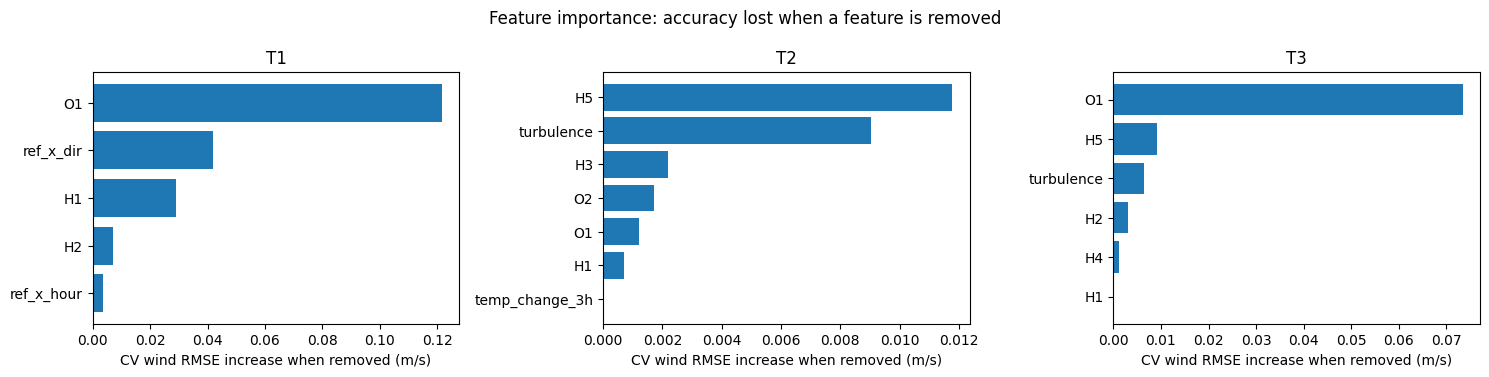

In [30]:
def importance(t):
    F, cols, ref_cols, model, ok = final[t]
    contrib = F[cols].mul(model.coef_, axis=1)
    groups = list(dict.fromkeys(group_of(c) for c in cols))
    base_pred = model_regression(t, F[cols], ref_cols)
    base = metrics(t, base_pred)
    rows = []
    for g in groups:
        g_cols = [c for c in cols if group_of(c) == g]
        keep = [c for c in cols if c not in g_cols]
        keep_refs = [c for c in ref_cols if c in keep]
        # score on the same rows as the full model, otherwise removing a reference with gaps
        # (e.g. H1, 13-15 Jul) adds hard hours to the evaluation and looks like lost accuracy
        dropped = metrics(t, model_regression(t, F[keep], keep_refs).where(base_pred.notna()))
        rows.append({"group": g,
                     "contribution_spread_ms": contrib.loc[ok, g_cols].sum(axis=1).std(),
                     "dropout_ws_rmse_+": dropped["ws_rmse"] - base["ws_rmse"],
                     "dropout_p_rmse_+": dropped["p_rmse"] - base["p_rmse"],
                     "meaning": describe(t, g)})
    out = pd.DataFrame(rows).set_index("group")
    out.insert(1, "spread_share_%", out["contribution_spread_ms"] / out["contribution_spread_ms"].sum() * 100)
    return out.sort_values("dropout_ws_rmse_+", ascending=False), base

imp = {}
for t in targets:
    imp[t], base = importance(t)
    print(f"===== {t}: CV wind RMSE {base['ws_rmse']:.3f} m/s, power RMSE {base['p_rmse']:.0f} kW")
    display(imp[t].round({"contribution_spread_ms": 3, "spread_share_%": 1, "dropout_ws_rmse_+": 3, "dropout_p_rmse_+": 1}))

fig, axes = plt.subplots(1, len(targets), figsize=(15, 3.8))
for ax, t in zip(axes, targets):
    s = imp[t]["dropout_ws_rmse_+"].sort_values()
    ax.barh(s.index, s.values)
    ax.set_title(t); ax.set_xlabel("CV wind RMSE increase when removed (m/s)")
plt.suptitle("Feature importance: accuracy lost when a feature is removed"); plt.tight_layout(); plt.show()

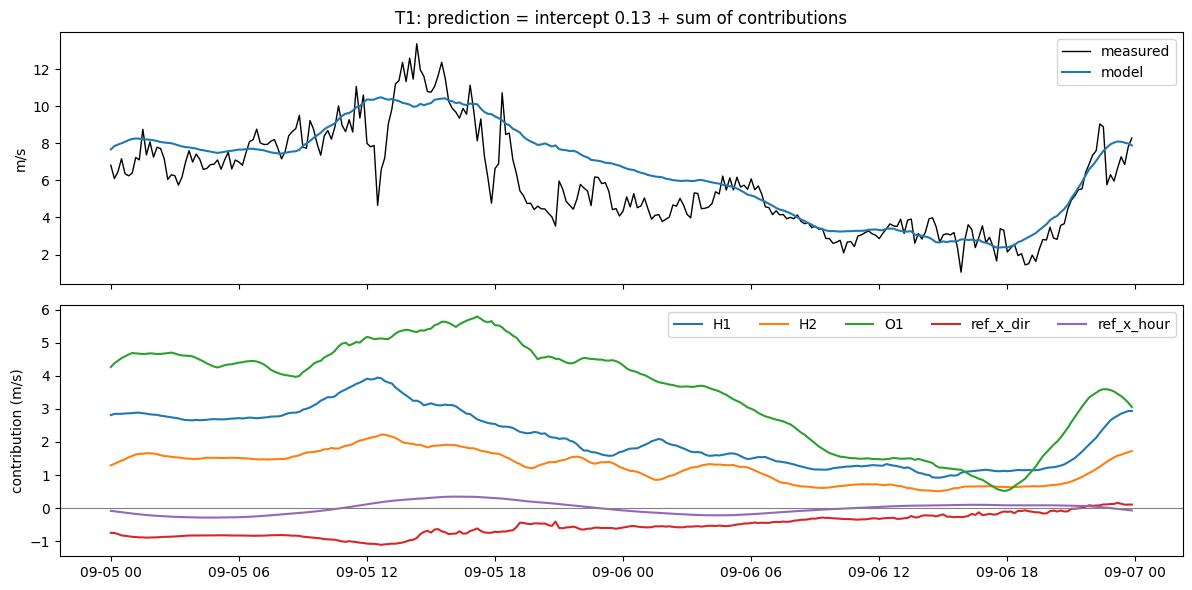

In [31]:
# How one prediction is built: contribution of each feature group over two days of the shown week
t = "T1"
F, cols, ref_cols, model, ok = final[t]
window = (full_idx >= "2026-09-05") & (full_idx < "2026-09-07")
contrib = F.loc[window, cols].mul(model.coef_, axis=1)
groups = contrib.T.groupby([group_of(c) for c in cols]).sum().T
pred = model.intercept_ + contrib.sum(axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(ws[t][window], color="black", lw=1, label="measured")
ax1.plot(pred, lw=1.5, label="model")
ax1.set_ylabel("m/s"); ax1.set_title(f"{t}: prediction = intercept {model.intercept_:.2f} + sum of contributions"); ax1.legend()
for g in groups:
    ax2.plot(groups[g], label=g)
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("contribution (m/s)"); ax2.legend(ncol=len(groups))
plt.tight_layout(); plt.show()

## Reference selection: which references does each target need?

**Rule:** fit the target on **all** references with weights ≥ 0, and keep the references whose weight is above 0.02.

- With weights forced ≥ 0, references that add nothing beyond the others get a weight of exactly 0. The fit does the selection itself, so there's no separate search and no tuning.
- **Stability:** refit 28 times, leaving out one 3-day block each time (the same blocks as CV). If a reference gets weight > 0.02 in (nearly) every refit, it is genuinely relevant, not a fluke.
- **Why drop the zero-weight references at all?** It doesn't change the prediction, since their weight is 0. But a model that lists them needs their data, so a gap in an unused reference would leave the prediction empty. Dropping them avoids that.

All subsets are scored on the **same rows**. Otherwise a reference with data gaps (H1, 13–15 Jul) looks useful only because removing it adds hard hours to the scoring.

In [32]:
MIN_WEIGHT = 0.02

def reference_table(t, window=WINDOW, min_weight=MIN_WEIGHT):
    """All references, weights >= 0: weight, share, and how stable the weight is across CV refits."""
    R = pd.DataFrame({r: smoothed_ref(t, r, window) for r in refs})
    rows = R.notna().all(axis=1) & ws[t].notna() & train_dev
    full = WeightedBoundedLinear(refs).fit(R[rows], ws[t][rows])
    folds = pd.DataFrame([WeightedBoundedLinear(refs).fit(R[rows & (block_id != b)], ws[t][rows & (block_id != b)]).coef_
                          for b in range(len(blocks))], columns=refs)
    lags = lag_table.query("target == @t").set_index("ref")
    tab = pd.DataFrame({"lag_min": lags["lag_min"], "corr": lags["corr"],
                        "weight": pd.Series(full.coef_, index=refs),
                        "weight_min": folds.min(), "weight_max": folds.max(),
                        "stability_%": (folds > min_weight).mean() * 100})
    tab["weight_share_%"] = tab["weight"] / tab["weight"].sum() * 100
    tab["used"] = tab["weight"] > min_weight
    return tab.sort_values("weight", ascending=False)

ref_tables = {t: reference_table(t) for t in targets}
relevant_refs = {t: list(tab.index[tab["used"]]) for t, tab in ref_tables.items()}

for t, tab in ref_tables.items():
    print(f"===== {t}: uses {relevant_refs[t]}")
    display(tab.round({"corr": 3, "weight": 3, "weight_min": 3, "weight_max": 3, "stability_%": 0, "weight_share_%": 1}))

===== T1: uses ['H1', 'O1', 'H2']


,lag_min,corr,weight,weight_min,weight_max,stability_%,weight_share_%,used
H1,-30,0.708,0.429,0.381,0.482,100.0,49.6,True
O1,0,0.722,0.380,0.371,0.405,100.0,43.9,True
H2,-20,0.659,0.056,0.008,0.088,96.0,6.5,True
H5,-30,0.694,0.000,0.000,0.000,0.0,0.0,False
H3,-30,0.685,0.000,0.000,0.000,0.0,0.0,False
O2,0,0.705,0.000,0.000,0.000,0.0,0.0,False
H4,-20,0.666,0.000,0.000,0.000,0.0,0.0,False


===== T2: uses ['O1', 'H5', 'O2', 'H3', 'H4', 'H2']


,lag_min,corr,weight,weight_min,weight_max,stability_%,weight_share_%,used
O1,0,0.789,0.257,0.224,0.292,100.0,28.8,True
H5,-30,0.764,0.195,0.145,0.221,100.0,21.9,True
O2,10,0.791,0.185,0.153,0.222,100.0,20.8,True
H3,-30,0.772,0.133,0.102,0.147,100.0,14.9,True
H4,-30,0.730,0.063,0.039,0.101,100.0,7.1,True
H2,-30,0.718,0.059,0.035,0.082,100.0,6.6,True
H1,-30,0.719,0.000,0.000,0.000,0.0,0.0,False


===== T3: uses ['O1', 'H2', 'H5', 'H4']


,lag_min,corr,weight,weight_min,weight_max,stability_%,weight_share_%,used
O1,0,0.761,0.367,0.344,0.372,100.0,44.1,True
H2,-30,0.717,0.177,0.154,0.199,100.0,21.3,True
H5,-30,0.742,0.144,0.112,0.164,100.0,17.3,True
H4,-30,0.722,0.143,0.117,0.164,100.0,17.2,True
O2,0,0.756,0.000,0.000,0.027,7.0,0.0,False
H1,-30,0.702,0.000,0.000,0.000,0.0,0.0,False
H3,-30,0.734,0.000,0.000,0.000,0.0,0.0,False


In [33]:
# Does dropping the unused references, or keeping fewer, change accuracy? (references only, same rows)
rows_out = []
for t in targets:
    R = pd.DataFrame({r: smoothed_ref(t, r, WINDOW) for r in refs})
    same_rows = R.notna().all(axis=1) & ws[t].notna()
    best_single = ref_tables[t]["corr"].idxmax()
    top3_corr = list(ref_tables[t]["corr"].sort_values(ascending=False).index[:3])
    for name, members in [("all 7", list(refs)), ("used (weight > 0.02)", relevant_refs[t]),
                          ("top 3 by correlation", top3_corr), ("best single", [best_single])]:
        f = weighted_predictor(t, R[members], members)
        cv = cv_predict(t, f).where(same_rows)
        sh = f(pd.Series(train_dev, index=full_idx), None)
        rows_out.append({"target": t, "setup": name, "refs": ", ".join(members),
                         **{f"cv_{k}": v for k, v in score(t, cv).items()},
                         **{f"shown_{k}": v for k, v in score(t, sh, shown).items()}})
ref_compare = pd.DataFrame(rows_out)
for col in ["cv_ws_rmse", "cv_p_rmse", "shown_ws_rmse", "shown_p_rmse", "shown_energy_dev_kwh"]:
    print(col)
    display(ref_compare.pivot(index="setup", columns="target", values=col).round(3 if "ws" in col else 0))

cv_ws_rmse


target,T1,T2,T3
setup,,,
all 7,1.247,1.085,1.080
best single,1.366,1.205,1.194
top 3 by correlation,1.245,1.093,1.095
used (weight > 0.02),1.247,1.085,1.080


cv_p_rmse


target,T1,T2,T3
setup,,,
all 7,716.0,638.0,613.0
best single,768.0,695.0,660.0
top 3 by correlation,714.0,644.0,624.0
used (weight > 0.02),716.0,639.0,613.0


shown_ws_rmse


target,T1,T2,T3
setup,,,
all 7,1.551,1.182,1.300
best single,1.721,1.375,1.452
top 3 by correlation,1.562,1.209,1.322
used (weight > 0.02),1.551,1.188,1.302


shown_p_rmse


target,T1,T2,T3
setup,,,
all 7,857.0,726.0,817.0
best single,948.0,831.0,890.0
top 3 by correlation,866.0,744.0,828.0
used (weight > 0.02),857.0,730.0,818.0


shown_energy_dev_kwh


target,T1,T2,T3
setup,,,
all 7,11202.0,1257.0,3205.0
best single,17721.0,590.0,7002.0
top 3 by correlation,11677.0,2316.0,4949.0
used (weight > 0.02),11202.0,1500.0,3517.0


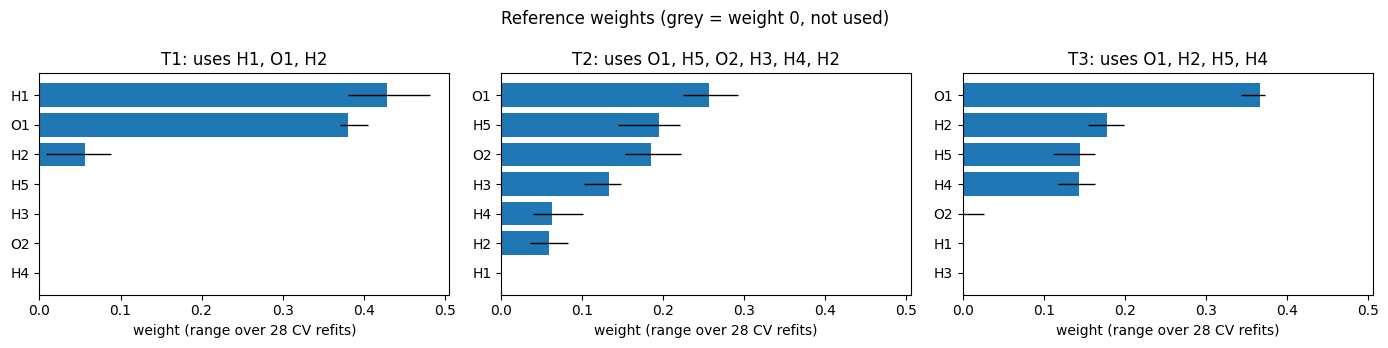

In [34]:
fig, axes = plt.subplots(1, len(targets), figsize=(14, 3.5), sharex=True)
for ax, t in zip(axes, targets):
    tab = ref_tables[t].sort_values("weight")
    ax.barh(tab.index, tab["weight"], color=np.where(tab["used"], "tab:blue", "lightgrey"))
    ax.errorbar(tab["weight"], tab.index, xerr=[tab["weight"] - tab["weight_min"], tab["weight_max"] - tab["weight"]],
                fmt="none", color="black", lw=1)
    ax.set_title(f"{t}: uses {', '.join(relevant_refs[t])}"); ax.set_xlabel("weight (range over 28 CV refits)")
plt.suptitle("Reference weights (grey = weight 0, not used)"); plt.tight_layout(); plt.show()

## Final comparison: relevant references vs. simple baselines

| Setup | What it is |
|---|---|
| A. Always the mean of T | Predict the target's training average at every step |
| D. Raw reference average | Plain average of all 7 references' wind speed: no lag, no smoothing, no fit |
| R1. All 7 references | Regression on all references (lag-shifted, 130-min smoothed, weights ≥ 0) |
| R2. Relevant references | Same, using only `relevant_refs` (weight > 0.02) |
| R3. R2 + extra features | Forward selection of direction / hour / turbulence corrections on top of R2 |
| G. Old model G | Backward elimination + forward selection (cell 36), for comparison |

All setups are scored on the **same rows**, both in CV (28 × 3-day blocks) and on the shown week (fit on `train_dev`, predict 4–9 Sep).
Energy uses expected power, the same as `src/`.

**Don't judge a setup by energy deviation alone.** "A. Always the mean" can hit the total energy almost exactly: spreading a constant over the error distribution just reproduces the average power, and errors cancel over a long period. But its wind RMSE is about 2× worse, and it would be wrong for any windier- or calmer-than-average outage.

In [35]:
def features_for(t, members, window=WINDOW):
    """Same features as build_features (cell 36), but for any list of references."""
    F = pd.DataFrame({f"ws_{r}": smoothed_ref(t, r, window) for r in members})
    ref_cols = list(F.columns)
    ref_avg = F[ref_cols].mean(axis=1)
    hour = full_idx.hour + full_idx.minute / 60
    F["hour_sin"], F["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    F["ref_x_hour_sin"], F["ref_x_hour_cos"] = ref_avg * F["hour_sin"], ref_avg * F["hour_cos"]
    rad = np.deg2rad(wide["wind_direction"][refs])
    F["dir_sin"], F["dir_cos"] = np.sin(rad).mean(axis=1), np.cos(rad).mean(axis=1)
    F["ref_x_dir_sin"], F["ref_x_dir_cos"] = ref_avg * F["dir_sin"], ref_avg * F["dir_cos"]
    F["turbulence"] = wide["wind_speed_stddev"][h_park].mean(axis=1).rolling(window, center=True, min_periods=1).mean()
    F["temp_change_3h"] = wide["ambient_temperature"][h_park].mean(axis=1).diff(18)
    return F, ref_cols

def forward_select_extras(t, F, ref_cols, min_gain=0.002):
    """Add extra feature groups (candidates, cell 36) while CV wind RMSE improves by >= min_gain."""
    all_cols = ref_cols + [c for g in candidates.values() for c in g]
    rows = F[all_cols].notna().all(axis=1) & ws[t].notna()          # same rows for every trial
    rmse = lambda cols: score(t, cv_predict(t, weighted_predictor(t, F[cols], ref_cols)).where(rows))["ws_rmse"]
    cols, remaining, best = list(ref_cols), dict(candidates), rmse(ref_cols)
    history = [("references only", best)]
    while remaining:
        trials = {g: rmse(cols + c) for g, c in remaining.items()}
        g = min(trials, key=trials.get)
        if (best - trials[g]) / best < min_gain:
            break
        cols += remaining.pop(g); best = trials[g]; history.append((f"+ {g}", best))
    return cols, history

final_models = {}
for t in targets:
    F, ref_cols = features_for(t, relevant_refs[t])
    cols, history = forward_select_extras(t, F, ref_cols)
    final_models[t] = (F, cols, ref_cols)
    print(f"{t}: references {relevant_refs[t]} | " + " -> ".join(f"{s} {r:.3f}" for s, r in history))

T1: references ['H1', 'O1', 'H2'] | references only 1.246 -> + ref_x_dir 1.203 -> + ref_x_hour 1.200
T2: references ['O1', 'H5', 'O2', 'H3', 'H4', 'H2'] | references only 1.116 -> + turbulence 1.101
T3: references ['O1', 'H2', 'H5', 'H4'] | references only 1.107 -> + turbulence 1.100


In [40]:
def compare_setups(t):
    F_all, all_cols = features_for(t, list(refs))
    F, cols, ref_cols = final_models[t]
    F_g, _ = build_features(t)
    g_cols, g_refs = selected[t]
    predictors = {
        "A. Always the mean of T":     lambda fit, test: pd.Series(ws[t][fit].mean(), index=full_idx),
        "D. Raw reference average":    lambda fit, test: ws[refs].mean(axis=1),
        "R1. All 7 references":        weighted_predictor(t, F_all[all_cols], all_cols),
        "R2. Relevant references":     weighted_predictor(t, F[ref_cols], ref_cols),
        "R3. R2 + extra features":     weighted_predictor(t, F[cols], ref_cols),
        "G. Old model G":              weighted_predictor(t, F_g[g_cols], g_refs),
    }
    cv = {n: cv_predict(t, f) for n, f in predictors.items()}
    sh = {n: f(pd.Series(train_dev, index=full_idx), shown) for n, f in predictors.items()}
    same_cv = pd.concat(cv, axis=1).notna().all(axis=1)                 # rows every setup predicted
    same_sh = pd.concat(sh, axis=1).notna().all(axis=1) & shown
    return pd.DataFrame([{"setup": n,
                          **{f"cv_{k}": v for k, v in score(t, cv[n], same_cv).items()},
                          **{f"shown_{k}": v for k, v in score(t, sh[n], same_sh).items()}}
                         for n in predictors]).set_index("setup")

final_compare = pd.concat({t: compare_setups(t) for t in targets}, names=["target"]).reset_index()
for col, d in [("cv_ws_rmse", 3), ("cv_p_rmse", 0), ("cv_energy_dev_kwh", 0),
               ("shown_ws_rmse", 3), ("shown_p_rmse", 0), ("shown_energy_dev_kwh", 0)]:
    print(col)
    display(final_compare.pivot(index="setup", columns="target", values=col).round(d))

cv_ws_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,2.099,2.181,2.005
D. Raw reference average,1.557,1.267,1.429
G. Old model G,1.201,1.065,1.073
R1. All 7 references,1.247,1.082,1.080
R2. Relevant references,1.247,1.083,1.080
R3. R2 + extra features,1.201,1.066,1.073


cv_p_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,1085.0,1144.0,1003.0
D. Raw reference average,800.0,703.0,703.0
G. Old model G,686.0,621.0,605.0
R1. All 7 references,716.0,637.0,613.0
R2. Relevant references,716.0,638.0,613.0
R3. R2 + extra features,686.0,623.0,605.0


cv_energy_dev_kwh


...

target,T1,T2,T3
setup,,,
A. Always the mean of T,2.725,3.243,3.007
D. Raw reference average,2.210,1.299,1.650
G. Old model G,1.490,1.163,1.290
R1. All 7 references,1.551,1.182,1.300
R2. Relevant references,1.551,1.188,1.302
R3. R2 + extra features,1.490,1.175,1.292


shown_p_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,1394.0,1473.0,1395.0
D. Raw reference average,939.0,751.0,863.0
G. Old model G,855.0,716.0,807.0
R1. All 7 references,857.0,726.0,817.0
R2. Relevant references,857.0,730.0,818.0
R3. R2 + extra features,855.0,724.0,808.0


shown_energy_dev_kwh


target,T1,T2,T3
setup,,,
A. Always the mean of T,76.0,112.0,-251.0
D. Raw reference average,20979.0,-2196.0,7134.0
G. Old model G,9839.0,-2118.0,2046.0
R1. All 7 references,11202.0,1257.0,3205.0
R2. Relevant references,11202.0,1500.0,3517.0
R3. R2 + extra features,9839.0,-1557.0,2257.0


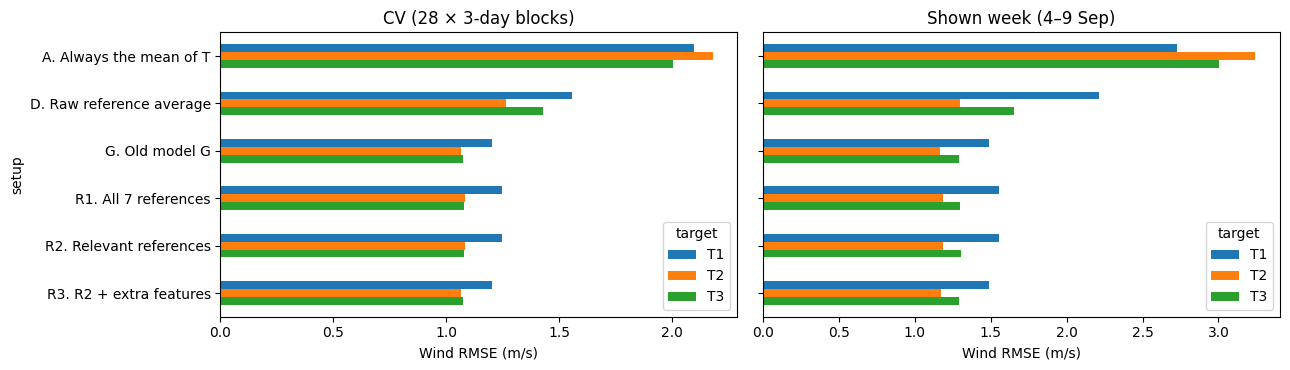

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, title in [(axes[0], "cv_ws_rmse", "CV (28 × 3-day blocks)"), (axes[1], "shown_ws_rmse", "Shown week (4–9 Sep)")]:
    p = final_compare.pivot(index="setup", columns="target", values=col)
    p.plot.barh(ax=ax)
    ax.set_title(title); ax.set_xlabel("Wind RMSE (m/s)"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [42]:
for col, d in [("cv_ws_rmse", 3), ("cv_p_rmse_point", 0), ("cv_p_rmse", 0),
               ("cv_energy_dev_kwh_point", 0), ("cv_energy_dev_kwh", 0),
               ("shown_ws_rmse", 3), ("shown_p_rmse_point", 0), ("shown_p_rmse", 0),
               ("shown_energy_dev_kwh_point", 0), ("shown_energy_dev_kwh", 0)]:
    print(col)
    display(final_compare.pivot(index="setup", columns="target", values=col).round(d))


cv_ws_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,2.099,2.181,2.005
D. Raw reference average,1.557,1.267,1.429
G. Old model G,1.201,1.065,1.073
R1. All 7 references,1.247,1.082,1.080
R2. Relevant references,1.247,1.083,1.080
R3. R2 + extra features,1.201,1.066,1.073


cv_p_rmse_point


target,T1,T2,T3
setup,,,
A. Always the mean of T,1124.0,1190.0,1038.0
D. Raw reference average,909.0,748.0,849.0
G. Old model G,696.0,630.0,613.0
R1. All 7 references,727.0,646.0,620.0
R2. Relevant references,727.0,647.0,620.0
R3. R2 + extra features,696.0,633.0,613.0


cv_p_rmse


...

target,T1,T2,T3
setup,,,
A. Always the mean of T,1394.0,1473.0,1395.0
D. Raw reference average,939.0,751.0,863.0
G. Old model G,855.0,716.0,807.0
R1. All 7 references,857.0,726.0,817.0
R2. Relevant references,857.0,730.0,818.0
R3. R2 + extra features,855.0,724.0,808.0


shown_energy_dev_kwh_point


target,T1,T2,T3
setup,,,
A. Always the mean of T,-111764.0,-194529.0,-174117.0
D. Raw reference average,123334.0,24263.0,64828.0
G. Old model G,26211.0,-3488.0,-10655.0
R1. All 7 references,42557.0,-1818.0,-10031.0
R2. Relevant references,42557.0,-2117.0,-9640.0
R3. R2 + extra features,26211.0,-4246.0,-10194.0


shown_energy_dev_kwh


target,T1,T2,T3
setup,,,
A. Always the mean of T,76.0,112.0,-251.0
D. Raw reference average,20979.0,-2196.0,7134.0
G. Old model G,9839.0,-2118.0,2046.0
R1. All 7 references,11202.0,1257.0,3205.0
R2. Relevant references,11202.0,1500.0,3517.0
R3. R2 + extra features,9839.0,-1557.0,2257.0


In [43]:
# Floor 1: a model that knew T's own 130-min mean wind perfectly; only the 10-min gusts are left
# Floor 2: predicting T from its own park neighbours (not available in an outage); "if references were as close as T2/T3"
rows = []
for t in targets:
    y = ws[t]
    smooth_self = y.rolling(13, center=True, min_periods=7).mean()
    neighbours = [n for n in targets if n != t]
    Xn = pd.DataFrame({n: smoothed_ref(t, n, 1) for n in neighbours}) if False else ws[neighbours]
    f_nb = weighted_predictor(t, Xn, neighbours)
    sh_nb = f_nb(pd.Series(train_dev, index=full_idx), shown)
    F, cols, ref_cols = final_models[t]
    sh_r3 = weighted_predictor(t, F[cols], ref_cols)(pd.Series(train_dev, index=full_idx), shown)
    for name, pred in [("R3 (our model)", sh_r3), ("floor: own 130-min mean", smooth_self),
                       ("floor: park neighbours", sh_nb)]:
        s = score(t, pred, shown)
        rows.append({"target": t, "setup": name, "ws_rmse": s["ws_rmse"], "p_rmse_point": s["p_rmse_point"]})
floor = pd.DataFrame(rows)
for col in ["ws_rmse", "p_rmse_point"]:
    print(f"shown week, {col}")
    display(floor.pivot(index="setup", columns="target", values=col).round(3 if "ws" in col else 0))


shown week, ws_rmse


target,T1,T2,T3
setup,,,
R3 (our model),1.490,1.175,1.292
floor: own 130-min mean,0.863,0.769,0.842
floor: park neighbours,1.444,1.007,0.975


shown week, p_rmse_point


target,T1,T2,T3
setup,,,
R3 (our model),900.0,748.0,839.0
floor: own 130-min mean,534.0,488.0,532.0
floor: park neighbours,897.0,696.0,684.0


In [44]:
from sklearn.ensemble import HistGradientBoostingRegressor

def add_harmonics(t, F, cols, ref_cols, ks=(2, 3, 4)):
    """R3 + ref_avg * sin/cos(k * O-park direction): lets the model follow T1's wake dips."""
    F = F.copy(); ref_avg = F[ref_cols].mean(axis=1); th = np.deg2rad(dir_O)
    new = []
    for k in ks:
        F[f"h_sin{k}"], F[f"h_cos{k}"] = ref_avg * np.sin(k * th), ref_avg * np.cos(k * th)
        new += [f"h_sin{k}", f"h_cos{k}"]
    return F, cols + new

def gbm_predictor(t, X):
    """Black-box challenger on the same features."""
    has = X.notna().all(axis=1)
    def f(fit, test):
        ok = fit & has & ws[t].notna()
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0)
        m.fit(X[ok], ws[t][ok])
        out = pd.Series(np.nan, index=full_idx); out[has] = m.predict(X[has]); return out
    return f

def calibrated_power(t, pred_fit, pred_new, step=0.5):
    """Learned power curve: mean measured power for each 0.5 m/s bin of *predicted* wind (from CV on train_dev)."""
    ok = pred_fit.notna() & ws[t].notna() & train_dev
    bins = np.arange(0, pred_fit[ok].max() + step, step)
    table = pd.Series(wind_to_power(ws[t][ok].values), index=ws[t][ok].index).groupby(pd.cut(pred_fit[ok], bins), observed=True).mean()
    return np.interp(pred_new, [iv.mid for iv in table.index], table.values)

rows = []
for t in targets:
    F, cols, ref_cols = final_models[t]
    Fh, cols_h = add_harmonics(t, F, cols, ref_cols)
    setups = {"R3": weighted_predictor(t, F[cols], ref_cols),
              "R3 + direction harmonics": weighted_predictor(t, Fh[cols_h], ref_cols),
              "GBM (same features + harmonics)": gbm_predictor(t, Fh[cols_h])}
    for name, f in setups.items():
        cv = cv_predict(t, f)
        sh = f(pd.Series(train_dev, index=full_idx), shown)
        s_cv, s_sh = score(t, cv), score(t, sh, shown)
        ev = sh.notna() & ws[t].notna() & shown
        p_cal = calibrated_power(t, cv, sh[ev].clip(0).values)
        p_cal_rmse = np.sqrt(((p_cal - wind_to_power(ws[t][ev].values)) ** 2).mean())
        rows.append({"target": t, "setup": name,
                     "cv_ws_rmse": s_cv["ws_rmse"], "cv_p_rmse_point": s_cv["p_rmse_point"],
                     "shown_ws_rmse": s_sh["ws_rmse"], "shown_p_rmse_point": s_sh["p_rmse_point"],
                     "shown_p_rmse_expected": s_sh["p_rmse"], "shown_p_rmse_calibrated": p_cal_rmse})
improve = pd.DataFrame(rows)
for col in ["cv_ws_rmse", "cv_p_rmse_point", "shown_ws_rmse", "shown_p_rmse_point", "shown_p_rmse_expected", "shown_p_rmse_calibrated"]:
    print(col)
    display(improve.pivot(index="setup", columns="target", values=col).round(3 if "ws" in col else 0))


cv_ws_rmse


target,T1,T2,T3
setup,,,
GBM (same features + harmonics),1.198,1.153,1.139
R3,1.201,1.103,1.102
R3 + direction harmonics,1.166,1.106,1.098


cv_p_rmse_point


target,T1,T2,T3
setup,,,
GBM (same features + harmonics),702.0,666.0,625.0
R3,696.0,644.0,621.0
R3 + direction harmonics,666.0,647.0,614.0


shown_ws_rmse


...

target,T1,T2,T3
setup,,,
GBM (same features + harmonics),795.0,747.0,825.0
R3,900.0,748.0,839.0
R3 + direction harmonics,840.0,757.0,840.0


shown_p_rmse_expected


target,T1,T2,T3
setup,,,
GBM (same features + harmonics),775.0,731.0,804.0
R3,855.0,724.0,808.0
R3 + direction harmonics,799.0,730.0,810.0


shown_p_rmse_calibrated


target,T1,T2,T3
setup,,,
GBM (same features + harmonics),809.0,841.0,871.0
R3,905.0,722.0,815.0
R3 + direction harmonics,840.0,741.0,817.0


## Modellign
Each Turbines relevant reference + Forward Selection of Features and Direction harmonics

In [45]:
# Model R4: relevant references + forward selection, with direction harmonics as an extra candidate group
def circmean(df):
    x = np.deg2rad(df)
    return np.rad2deg(np.arctan2(np.sin(x).mean(axis=1), np.cos(x).mean(axis=1))) % 360

dir_O = circmean(wide["wind_direction"][["O1", "O2"]])      # O-park direction: available during an outage

HARMONIC_COLS = [f"h_{f}{k}" for k in (2, 3, 4) for f in ("sin", "cos")]
candidates_h = {**candidates, "dir_harmonics": HARMONIC_COLS}

def features_with_harmonics(t, members):
    """features_for + ref_avg * sin/cos(k * O-park direction), k = 2, 3, 4."""
    F, ref_cols = features_for(t, members)
    ref_avg = F[ref_cols].mean(axis=1)
    th = np.deg2rad(dir_O)
    for k in (2, 3, 4):
        F[f"h_sin{k}"] = ref_avg * np.sin(k * th)
        F[f"h_cos{k}"] = ref_avg * np.cos(k * th)
    return F, ref_cols

def select_extras(t, F, ref_cols, cands, min_gain=0.002):
    """Add extra feature groups while CV wind RMSE improves by >= min_gain (scored on the same rows)."""
    all_cols = ref_cols + [c for g in cands.values() for c in g]
    rows = F[all_cols].notna().all(axis=1) & ws[t].notna()
    rmse = lambda cols: score(t, cv_predict(t, weighted_predictor(t, F[cols], ref_cols)).where(rows))["ws_rmse"]
    cols, remaining, best = list(ref_cols), dict(cands), rmse(ref_cols)
    history = [("references only", best)]
    while remaining:
        trials = {g: rmse(cols + c) for g, c in remaining.items()}
        g = min(trials, key=trials.get)
        if (best - trials[g]) / best < min_gain:
            break
        cols += remaining.pop(g); best = trials[g]; history.append((f"+ {g}", best))
    return cols, history

models_h = {}
for t in targets:
    F, ref_cols = features_with_harmonics(t, relevant_refs[t])
    cols, history = select_extras(t, F, ref_cols, candidates_h)
    models_h[t] = (F, cols, ref_cols)
    print(f"{t}: " + " -> ".join(f"{s} {r:.3f}" for s, r in history))


T1: references only 1.246 -> + dir_harmonics 1.197 -> + ref_x_dir 1.169 -> + turbulence 1.164
T2: references only 1.116 -> + turbulence 1.101
T3: references only 1.107 -> + turbulence 1.100 -> + dir_harmonics 1.096


In [46]:
def compare_with_harmonics(t):
    F_all, all_cols = features_for(t, list(refs))
    F3, cols3, refs3 = final_models[t]
    F4, cols4, refs4 = models_h[t]
    predictors = {
        "A. Always the mean of T":      lambda fit, test: pd.Series(ws[t][fit].mean(), index=full_idx),
        "D. Raw reference average":     lambda fit, test: ws[refs].mean(axis=1),
        "R1. All 7 references":         weighted_predictor(t, F_all[all_cols], all_cols),
        "R3. Relevant refs + extras":   weighted_predictor(t, F3[cols3], refs3),
        "R4. R3 + direction harmonics": weighted_predictor(t, F4[cols4], refs4),
    }
    cv = {n: cv_predict(t, f) for n, f in predictors.items()}
    sh = {n: f(pd.Series(train_dev, index=full_idx), shown) for n, f in predictors.items()}
    same_cv = pd.concat(cv, axis=1).notna().all(axis=1)                 # every setup scored on the same rows
    same_sh = pd.concat(sh, axis=1).notna().all(axis=1) & shown
    table = pd.DataFrame([{"setup": n,
                           **{f"cv_{k}": v for k, v in score(t, cv[n], same_cv).items()},
                           **{f"shown_{k}": v for k, v in score(t, sh[n], same_sh).items()}}
                          for n in predictors]).set_index("setup")
    return table, sh

results_h, shown_preds = {}, {}
for t in targets:
    results_h[t], shown_preds[t] = compare_with_harmonics(t)
harm_compare = pd.concat(results_h, names=["target"]).reset_index()

for col, d in [("cv_ws_rmse", 3), ("cv_p_rmse_point", 0), ("cv_p_rmse", 0), ("cv_energy_dev_kwh", 0),
               ("shown_ws_rmse", 3), ("shown_p_rmse_point", 0), ("shown_p_rmse", 0), ("shown_energy_dev_kwh", 0)]:
    print(col)
    display(harm_compare.pivot(index="setup", columns="target", values=col).round(d))


cv_ws_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,2.099,2.184,2.005
D. Raw reference average,1.557,1.272,1.429
R1. All 7 references,1.247,1.085,1.080
R3. Relevant refs + extras,1.201,1.070,1.073
R4. R3 + direction harmonics,1.166,1.070,1.069


cv_p_rmse_point


target,T1,T2,T3
setup,,,
A. Always the mean of T,1124.0,1190.0,1038.0
D. Raw reference average,909.0,751.0,849.0
R1. All 7 references,727.0,647.0,620.0
R3. Relevant refs + extras,696.0,635.0,613.0
R4. R3 + direction harmonics,666.0,635.0,607.0


cv_p_rmse


...

target,T1,T2,T3
setup,,,
A. Always the mean of T,1595.0,1999.0,1846.0
D. Raw reference average,1386.0,799.0,1035.0
R1. All 7 references,945.0,747.0,846.0
R3. Relevant refs + extras,900.0,748.0,839.0
R4. R3 + direction harmonics,834.0,748.0,840.0


shown_p_rmse


target,T1,T2,T3
setup,,,
A. Always the mean of T,1394.0,1473.0,1395.0
D. Raw reference average,939.0,751.0,863.0
R1. All 7 references,857.0,726.0,817.0
R3. Relevant refs + extras,855.0,724.0,808.0
R4. R3 + direction harmonics,794.0,724.0,810.0


shown_energy_dev_kwh


target,T1,T2,T3
setup,,,
A. Always the mean of T,76.0,112.0,-251.0
D. Raw reference average,20979.0,-2196.0,7134.0
R1. All 7 references,11202.0,1257.0,3205.0
R3. Relevant refs + extras,9839.0,-1557.0,2257.0
R4. R3 + direction harmonics,10045.0,-1557.0,2427.0


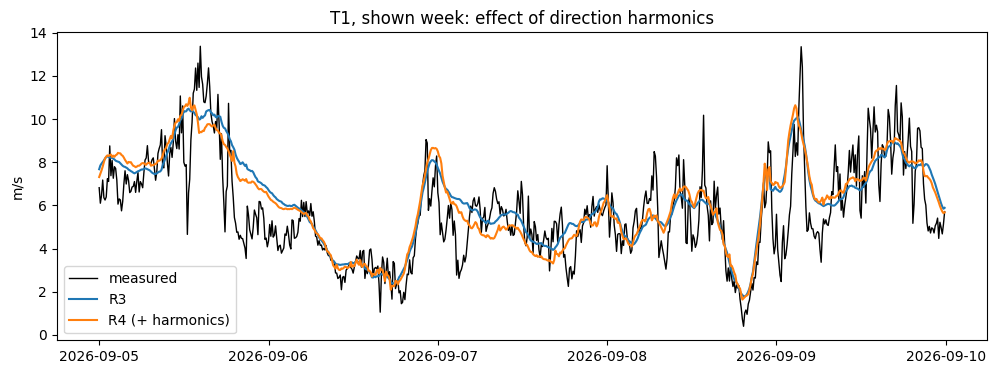

In [50]:
t = "T1"
win = shown & (full_idx >= "2026-09-05") & (full_idx < "2026-09-10")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(full_idx[win], ws[t][win], color="black", lw=1, label="measured")
ax.plot(full_idx[win], shown_preds[t]["R3. Relevant refs + extras"][win], lw=1.5, label="R3")
ax.plot(full_idx[win], shown_preds[t]["R4. R3 + direction harmonics"][win], lw=1.5, label="R4 (+ harmonics)")
ax.set_ylabel("m/s"); ax.set_title(f"{t}, shown week: effect of direction harmonics"); ax.legend()
plt.show()

